Step 1: Define the Generic Governing FormulaStart with a general evolution equation (ordinary or partial differential equation):   $$\frac{\partial u}{\partial t} = \mathcal{D}[u(x, t)]$$If you want to fit your neural network $u_\theta(x, t)$ to known data or boundary/initial references while respecting this system, you use the governing operator $\mathcal{D}$ to construct higher-order time derivatives. For example, the second-order derivative becomes:   $$\frac{\partial^2 u}{\partial t^2} = \frac{\partial \mathcal{D}[u]}{\partial t} = \frac{\partial \mathcal{D}}{\partial u} \frac{\partial u}{\partial t} = \frac{\partial \mathcal{D}}{\partial u} \mathcal{D}[u]$$Step 2: Build the Taylor Expansion Iteration FormulaTo link a state at time $t$ to its previous state at $t - \Delta t$, write the truncated Taylor series expansion:$$u(x, t) \approx u(x, t - \Delta t) + \sum_{j=1}^{k} \frac{\Delta t^j}{j!} \frac{\partial^{j-1} \mathcal{D}[u(x, t - \Delta t)]}{\partial t^{j-1}}$$This formula acts as an explicit recurrence constraint. It dictates that the network's prediction at time $t$ must match the Taylor expansion step propagated from $t - \Delta t$.Step 3: Define the Taylor Residual Loss ($\mathcal{L}_F$)To fit the neural network into this known iterative structure, define a specialized local residual $F(x, t)$:   $$F(x, t) = u_\theta(x, t) - \left( u_\theta(x, t - \Delta t) + \sum_{j=1}^{k} \frac{\Delta t^j}{j!} \frac{\partial^{j-1} \mathcal{D}[u_\theta(x, t - \Delta t)]}{\partial t^{j-1}} \right)$$The corresponding loss component is the Mean Squared Error of this residual over your collocation points:   $$\mathcal{L}_F = \frac{1}{N_f} \sum_{(x,t)} \vert{}F(x, t)\vert{}^2$$Step 4: Construct the Total Loss FunctionTo completely fit the function into both known data constraints and the Taylor iterative physics, combine your losses:$$\mathcal{L}(\theta) = w_u \mathcal{L}_{\text{data}} + w_i \mathcal{L}_{\text{init}} + w_b \mathcal{L}_{\text{bound}} + w_F \mathcal{L}_F$$$\mathcal{L}_{\text{data}}$: Fits $u_\theta$ to any known observations or target baseline functions.$\mathcal{L}_{\text{init}} / \mathcal{L}_{\text{bound}}$: Enforces initial conditions $u(x,0)$ and boundaries.$\mathcal{L}_F$: Enforces the Taylor iteration constraint linking adjacent time/space steps.Step 5: Implement a Forward Progressive Training LoopBecause Taylor expansions rely on local information ($\Delta t$), training stability is vastly improved by using a forward progressive time-domain decomposition:Train the network on the initial time interval $[0, T_1]$ using initial conditions and data fitting.Treat the predicted endpoint $u_\theta(x, T_1)$ as the pseudo-initial condition for the next interval $[T_1, T_2]$.Advance iteratively, minimizing the Taylor recurrence residual $F(x,t)$ across sequential segments.

In [1]:
import torch
import torch.nn as nn

class TaylorPINN(nn.Module):
    def __init__(self):
        super().__init__()
        # Standard MLP mapping (x, t) -> u
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.net(inputs)

def governing_operator(u, x, t):
    # Example placeholder for D[u]: e.g., Burgers or custom ODE/PDE right-hand side
    # Compute du/dx or derivatives using torch.autograd.grad
    du_dx = torch.autograd.grad(u, x, create_graph=True)[0]
    return -u * du_dx # Example nonlinear term

def taylor_residual_loss(model, x, t, dt, order=2):
    # Get state at t - dt and state at t
    u_prev = model(x, t - dt)
    u_curr_pred = model(x, t)
    
    # Compute operator at t - dt
    d_val = governing_operator(u_prev, x, t - dt)
    
    taylor_approx = u_prev + dt * d_val
    
    # If higher order is needed, compute higher derivatives of d_val with respect to t
    if order > 1:
        dd_dt = torch.autograd.grad(d_val, t, create_graph=True)[0]
        taylor_approx = taylor_approx + (dt**2 / 2.0) * dd_dt

    # The Taylor iteration residual constraint
    residual = u_curr_pred - taylor_approx
    return torch.mean(residual**2)

## Example

$$\frac{du}{dt} = -u^2, \quad u(0) = 1$$

In [2]:
import torch
import torch.nn as nn
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)

class TPINN(nn.Module):
    """Simple MLP mapping time t -> state u(t)"""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        
    def forward(self, t):
        return self.net(t)

# Initialize model, optimizer, and hyperparams
model = TPINN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

dt = 0.05       # Taylor time-step increment
epochs = 2000
batch_size = 64

print("Training Taylor-expansion PINN...")
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # 1. Initial Condition Loss: u(0) = 1
    t0 = torch.zeros((1, 1), requires_grad=True)
    u0_pred = model(t0)
    loss_ic = (u0_pred - 1.0) ** 2
    
    # 2. Taylor Recurrence Loss over domain t in [0, 1 - dt]
    t_current = torch.rand(batch_size, 1, requires_grad=True) * (1.0 - dt)
    t_next = t_current + dt
    
    u_curr = model(t_current)
    u_next_pred = model(t_next)
    
    # Governing operator D(u) = -u^2
    d_val = - (u_curr ** 2)
    
    # First-order time derivative of the operator using automatic differentiation (dD/dt)
    grad_d = torch.autograd.grad(d_val.sum(), t_current, create_graph=True)[0]
    
    # 2nd-order Taylor expansion approximation: u(t + dt) ≈ u(t) + dt*D(u) + (dt^2 / 2)*dD/dt
    taylor_approx = u_curr + dt * d_val + (0.5 * (dt ** 2)) * grad_d
    
    # Recurrence constraint loss
    loss_taylor = torch.mean((u_next_pred - taylor_approx) ** 2)
    
    # Total loss
    loss = loss_ic + loss_taylor
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 400 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e}")

# Compare against exact solution: u(t) = 1 / (1 + t)
t_test = torch.linspace(0.0, 1.0, 100).reshape(-1, 1)
with torch.no_grad():
    u_pred = model(t_test).numpy()
u_exact = 1.0 / (1.0 + t_test.numpy())

mse = np.mean((u_pred - u_exact) ** 2)
print(f"\nTraining completed! Final Mean Squared Error vs Exact Solution: {mse:.6e}")

Training Taylor-expansion PINN...
Epoch 400/2000 | Loss: 2.205583e-05
Epoch 800/2000 | Loss: 5.554067e-06
Epoch 1200/2000 | Loss: 3.064236e-06
Epoch 1600/2000 | Loss: 2.110741e-06
Epoch 2000/2000 | Loss: 1.178461e-06

Training completed! Final Mean Squared Error vs Exact Solution: 1.032234e-05


Method 1: Dictionary-Based Discovery (Sparse Regression / SINDy-PINN)If you suspect the unknown equation is a combination of standard mathematical terms (e.g., linear terms, non-linear powers like $u^2$, or spatial derivatives like $u_{xx}$), you can build a candidate library $\Theta(u)$.Define a Library of Candidate Terms:$$\mathcal{D}[u] = \sum_{k=1}^{m} \xi_k \Theta_k(u, \partial_x u, \partial_{xx} u, \dots)$$(Where $\xi_k$ are sparse coefficients to be discovered).Formulate the Taylor Residual:
Substitute this unknown library into your Taylor expansion framework:$$F(x, t) = u_\theta(x, t) - \left( u_\theta(x, t - \Delta t) + \sum_{j=1}^{k} \frac{\Delta t^j}{j!} \frac{\partial^{j-1} \Theta}{\partial t^{j-1}} \mathbf{\xi} \right)$$Joint Optimization with Sparsity:
Train the neural network $u_\theta$ to fit the data while simultaneously optimizing the coefficient vector $\mathbf{\xi}$ using an $L_1$ regularization penalty (lasso) to force out irrelevant terms, leaving only the true governing equation.Method 2: Neural Operator Parameterization (Function Approximation)If you have no intuition about what the equation looks like, you can replace the unknown operator $\mathcal{D}[u]$ with a secondary neural network $\mathcal{D}_\phi$ (a small auxiliary MLP).Dual Network Architecture:$u_\theta(x, t)$: The main network predicting the state field.$\mathcal{D}_\phi(u)$: An auxiliary network that acts as a black-box right-hand side $\frac{du}{dt} = \mathcal{D}_\phi(u)$.Taylor Recurrence Constraint:
Use the Taylor expansion with the auxiliary network's output:$$\text{Taylor Approx} = u_\theta(t) + \Delta t \cdot \mathcal{D}_\phi(u_\theta(t)) + \frac{\Delta t^2}{2} \frac{\partial \mathcal{D}_\phi}{\partial t}$$Loss Formulation:$$\mathcal{L} = \underbrace{\Vert{} u_\theta - u_{\text{data}} \Vert{}^2}_{\text{Data Fitting}} + \lambda \underbrace{\Vert{} u_\theta(t + \Delta t) - \text{Taylor Approx} \Vert{}^2}_{\text{Taylor Consistency}}$$

## Example 

$$\frac{du}{dt} = -1.5u$$

In [3]:
import torch
import torch.nn as nn
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)

# 1. Generate synthetic observational data from a hidden unknown law: du/dt = -1.5 * u
# True system trajectory: u(t) = exp(-1.5 * t) with slight noise added
t_data = torch.linspace(0.0, 1.0, 40).reshape(-1, 1)
u_true = torch.exp(-1.5 * t_data)
u_data = u_true + 0.01 * torch.randn_like(t_data)

# 2. Main State Network u_theta(t) -> maps time to state
class StateNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
    def forward(self, t):
        return self.net(t)

# 3. Auxiliary Operator Network D_phi(u) -> acts as the black-box unknown RHS equation
class OperatorNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 16),
            nn.Tanh(),
            nn.Linear(16, 1)
        )
    def forward(self, u):
        return self.net(u)

state_net = StateNetwork()
op_net = OperatorNetwork()

# Joint optimization over both network parameters
optimizer = torch.optim.Adam(
    list(state_net.parameters()) + list(op_net.parameters()), 
    lr=0.01
)

dt = 0.025
epochs = 3500

print("Training discovery TPINN with auxiliary operator network...")
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # A. Data Fitting Loss: match sparse observations
    u_pred_data = state_net(t_data)
    loss_data = torch.mean((u_pred_data - u_data) ** 2)
    
    # B. Taylor Recurrence Consistency Loss across the domain
    t_current = torch.rand(64, 1, requires_grad=True) * (1.0 - dt)
    t_next = t_current + dt
    
    u_curr = state_net(t_current)
    u_next_pred = state_net(t_next)
    
    # Evaluate the black-box auxiliary operator: D_phi(u)
    d_val = op_net(u_curr)
    
    # First-order time derivative of the operator via automatic differentiation (dD/dt)
    grad_d = torch.autograd.grad(d_val.sum(), t_current, create_graph=True)[0]
    
    # 2nd-order Taylor expansion step using the learned operator
    taylor_approx = u_curr + dt * d_val + (0.5 * (dt ** 2)) * grad_d
    
    loss_taylor = torch.mean((u_next_pred - taylor_approx) ** 2)
    
    # C. Initial Condition Loss Anchor at t = 0
    t0 = torch.zeros((1, 1), requires_grad=True)
    loss_ic = torch.mean((state_net(t0) - u_data[0]) ** 2)
    
    # Total loss combination
    loss = loss_data + 5.0 * loss_taylor + loss_ic
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 700 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Total Loss: {loss.item():.6e} | Data Loss: {loss_data.item():.6e}")

# 4. Evaluate Discovered Dynamics against True Dynamics (-1.5 * u)
u_test = torch.linspace(0.2, 1.0, 5).reshape(-1, 1)
with torch.no_grad():
    learned_rhs = op_net(u_test).numpy()
    true_rhs = -1.5 * u_test.numpy()

print("\n--- Discovered Operator vs True Operator (-1.5 * u) ---")
for uv, lr, tr in zip(u_test.numpy(), learned_rhs, true_rhs):
    print(f"State u: {uv[0]:.3f} | Learned D(u): {lr[0]:.4f} | True D(u): {tr[0]:.4f}")

Training discovery TPINN with auxiliary operator network...
Epoch 700/3500 | Total Loss: 1.211004e-04 | Data Loss: 1.156218e-04
Epoch 1400/3500 | Total Loss: 1.064398e-04 | Data Loss: 1.042763e-04
Epoch 2100/3500 | Total Loss: 1.022304e-04 | Data Loss: 1.020845e-04
Epoch 2800/3500 | Total Loss: 1.009710e-04 | Data Loss: 1.007715e-04
Epoch 3500/3500 | Total Loss: 1.540026e-04 | Data Loss: 1.269346e-04

--- Discovered Operator vs True Operator (-1.5 * u) ---
State u: 0.200 | Learned D(u): -0.3997 | True D(u): -0.3000
State u: 0.400 | Learned D(u): -0.5780 | True D(u): -0.6000
State u: 0.600 | Learned D(u): -0.8583 | True D(u): -0.9000
State u: 0.800 | Learned D(u): -1.2631 | True D(u): -1.2000
State u: 1.000 | Learned D(u): -1.7622 | True D(u): -1.5000


SINDy-Taylor PINN ArchitectureCandidate Library ($\Theta(u)$): Construct a feature matrix of possible mathematical terms evaluated at the network's state predictions. For a 1D state $u$, a polynomial library up to degree 3 looks like:$$\Theta(u) = \begin{bmatrix} 1 & u & u^2 & u^3 \end{bmatrix}$$Sparse Coefficient Vector ($\mathbf{\xi}$): A weight vector representing the contribution of each dictionary term to the governing operator:$$\mathcal{D}(u) = \Theta(u) \mathbf{\xi}$$Combined Loss Function: Minimize the data fit, the Taylor recurrence consistency, and an $L_1$ sparsity penalty ($\Vert{}\mathbf{\xi}\Vert{}_1$) to force out redundant terms.

In [4]:
import torch
import torch.nn as nn
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# 1. Generate synthetic data from hidden law: du/dt = -2.0 * u^2
# True solution: u(t) = 1.0 / (1.0 + 2.0 * t)
t_data = torch.linspace(0.0, 1.0, 50).reshape(-1, 1)
u_true = 1.0 / (1.0 + 2.0 * t_data)
u_data = u_true + 0.01 * torch.randn_like(t_data) # slight noise

# 2. State Network u_theta(t) with Xavier/Glorot initialization for stability
class StateNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        self._init_weights()
        
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
                
    def forward(self, t):
        return self.net(t)

state_net = StateNetwork()

# 3. SINDy Library Operator for D(u) = [1, u, u^2, u^3] * xi
class SindyLibraryOperator(nn.Module):
    def __init__(self):
        super().__init__()
        # Initialize coefficients close to zero
        self.xi = nn.Parameter(torch.zeros(4, 1))
        
    def forward(self, u):
        ones = torch.ones_like(u)
        Theta = torch.cat([ones, u, u**2, u**3], dim=1)
        return torch.matmul(Theta, self.xi)

sindy_op = SindyLibraryOperator()

optimizer = torch.optim.Adam(
    list(state_net.parameters()) + list(sindy_op.parameters()), 
    lr=0.005
)

dt = 0.02
epochs = 5000

print("Training stable 1st-order SINDy-Taylor PINN...")
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # A. Data Fitting Loss
    u_pred_data = state_net(t_data)
    loss_data = torch.mean((u_pred_data - u_data) ** 2)
    
    # B. 1st-Order Taylor Recurrence Consistency Loss
    # u(t + dt) ≈ u(t) + dt * D(u(t))
    t_current = torch.rand(64, 1, requires_grad=True) * (1.0 - dt)
    t_next = t_current + dt
    
    u_curr = state_net(t_current)
    u_next_pred = state_net(t_next)
    
    # Evaluate Sindy operator D(u)
    d_val = sindy_op(u_curr)
    
    # 1st-order Taylor approximation
    taylor_approx = u_curr + dt * d_val
    loss_taylor = torch.mean((u_next_pred - taylor_approx) ** 2)
    
    # C. Initial Condition Loss
    t0 = torch.zeros((1, 1), requires_grad=True)
    loss_ic = torch.mean((state_net(t0) - u_data[0]) ** 2)
    
    # D. L1 Sparsity Penalty on coefficients
    loss_sparsity = torch.sum(torch.abs(sindy_op.xi))
    
    # Combined Loss (balanced weights)
    loss = loss_data + 10.0 * loss_taylor + 5.0 * loss_ic + 0.0005 * loss_sparsity
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 1000 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e} | Coeffs: {sindy_op.xi.detach().numpy().flatten()}")

# Threshold small coefficients post-training
with torch.no_grad():
    sindy_op.xi.data[torch.abs(sindy_op.xi.data) < 0.05] = 0.0

# Print Discovered Algebraic Equation
terms = ["1", "u", "u^2", "u^3"]
coeffs = sindy_op.xi.detach().numpy().flatten()
equation_str = " + ".join([f"{c:.4f}*{t}" for c, t in zip(coeffs, terms) if abs(c) > 1e-3])

print("\n--- Discovered Governing Equation ---")
print(f"du/dt = {equation_str}")

Training stable 1st-order SINDy-Taylor PINN...
Epoch 1000/5000 | Loss: 1.559976e-03 | Coeffs: [-0.25547025 -0.35839692 -0.2991849  -0.18862295]
Epoch 2000/5000 | Loss: 1.033679e-03 | Coeffs: [-0.00108518 -0.7876964  -0.50029683 -0.00875286]
Epoch 3000/5000 | Loss: 8.629913e-04 | Coeffs: [-2.3940520e-04 -8.5899097e-01 -4.0515766e-01 -1.6518807e-02]
Epoch 4000/5000 | Loss: 9.826859e-04 | Coeffs: [-0.00185701 -0.8656228  -0.45131388 -0.0021408 ]
Epoch 5000/5000 | Loss: 9.366986e-04 | Coeffs: [-0.01289041 -0.86349684 -0.41860342 -0.01994634]

--- Discovered Governing Equation ---
du/dt = -0.8635*u + -0.4186*u^2


In [5]:
import numpy as np
from scipy.integrate import solve_ivp

# 1. Extract learned coefficients from the trained SINDy operator
# Assuming 'coeffs' array from the previous step looks like [c0, c1, c2, c3]
# Corresponding to terms: 1, u, u^2, u^3
# For du/dt = -2.0 * u^2, expected coeffs are roughly [0, 0, -2.0, 0]
learned_coeffs = sindy_op.xi.detach().numpy().flatten()

print("Extracted SINDy Coefficients:")
terms = ["1", "u", "u^2", "u^3"]
for t, c in zip(terms, learned_coeffs):
    print(f"  {t}: {c:.6f}")

# 2. Define the discovered right-hand side function for SciPy
def discovered_ode(t, y):
    u = y[0]
    # Reconstruct: D(u) = xi_0 + xi_1*u + xi_2*u^2 + xi_3*u^3
    dudt = learned_coeffs[0] + learned_coeffs[1]*u + learned_coeffs[2]*(u**2) + learned_coeffs[3]*(u**3)
    return [dudt]

# 3. Generate independent test data (unseen time points, e.g., finer grid or shifted range)
t_test = np.linspace(0.0, 1.0, 100)
u_true_test = 1.0 / (1.0 + 2.0 * t_test) # True analytical solution

# A. Evaluate Neural Network Interpolation on Test Points
with torch.no_grad():
    t_test_tensor = torch.tensor(t_test, dtype=torch.float32).reshape(-1, 1)
    u_pred_net = state_net(t_test_tensor).numpy().flatten()

nn_mse = np.mean((u_pred_net - u_true_test) ** 2)
print(f"\nNeural Network Test MSE: {nn_mse:.6e}")

# B. Evaluate Discovered Equation via Forward Rollout (SciPy ODE Solver)
# Start from initial condition u(0) = 1.0
sol = solve_ivp(discovered_ode, [0.0, 1.0], [1.0], t_eval=t_test)
u_pred_sindy = sol.y[0]

sindy_mse = np.mean((u_pred_sindy - u_true_test) ** 2)
print(f"Discovered Equation Rollout Test MSE: {sindy_mse:.6e}")

# Calculate Relative L2 Error
relative_l2 = np.linalg.norm(u_pred_sindy - u_true_test) / np.linalg.norm(u_true_test)
print(f"Discovered Equation Relative L2 Error: {relative_l2 * 100:.2f}%")

Extracted SINDy Coefficients:
  1: 0.000000
  u: -0.863497
  u^2: -0.418603
  u^3: 0.000000

Neural Network Test MSE: 3.517684e-05
Discovered Equation Rollout Test MSE: 2.212574e-03
Discovered Equation Relative L2 Error: 8.12%


In [6]:
import torch
import torch.nn as nn
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

# 1. Generate Input-Output Data from an Unknown Black-Box System
# Hidden true law: du/dt = -2.0 * sin(u), with u(0) = 1.5
t_data = torch.linspace(0.0, 1.5, 50).reshape(-1, 1)

# Simulating the hidden true trajectory numerically for synthetic data
u_list = [1.5]
dt_sim = t_data[1].item() - t_data[0].item()
for _ in range(len(t_data) - 1):
    u_prev = u_list[-1]
    u_next = u_prev + dt_sim * (-2.0 * np.sin(u_prev))
    u_list.append(u_next)
u_true = torch.tensor(u_list, dtype=torch.float32).reshape(-1, 1)
u_data = u_true + 0.01 * torch.randn_like(u_true)  # Add observation noise

# 2. State Trajectory Network: u_theta(t) -> maps time to state
class StateNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
    def forward(self, t):
        return self.net(t)

# 3. Black-Box Inner Operator Network: D_phi(u) -> unconstrained MLP acting as the unknown RHS
class BlackBoxOperator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
    def forward(self, u):
        return self.net(u)

state_net = StateNetwork()
blackbox_op = BlackBoxOperator()

optimizer = torch.optim.Adam(
    list(state_net.parameters()) + list(blackbox_op.parameters()), 
    lr=0.005
)

dt = 0.03
epochs = 4000

print("Training Taylor Black-Box Inner Dynamics Network...")
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # A. Data Fitting Loss: Match input-output observations
    u_pred_data = state_net(t_data)
    loss_data = torch.mean((u_pred_data - u_data) ** 2)
    
    # B. Taylor Recurrence Consistency Loss using Black-Box Operator
    t_current = torch.rand(64, 1, requires_grad=True) * (t_data[-1].item() - dt)
    t_next = t_current + dt
    
    u_curr = state_net(t_current)
    u_next_pred = state_net(t_next)
    
    # Evaluate unknown black-box inner dynamics
    d_val = blackbox_op(u_curr)
    
    # 1st-order Taylor expansion step
    taylor_approx = u_curr + dt * d_val
    loss_taylor = torch.mean((u_next_pred - taylor_approx) ** 2)
    
    # C. Initial Condition Anchor at t = 0
    t0 = torch.zeros((1, 1), requires_grad=True)
    loss_ic = torch.mean((state_net(t0) - u_data[0]) ** 2)
    
    # Total loss combining data fit and Taylor consistency
    loss = loss_data + 10.0 * loss_taylor + 5.0 * loss_ic
    loss.backward()
    optimizer.step()

# 4. Evaluate the Learned Black-Box Inner Equation vs True Equation (-2 * sin(u))
u_test = torch.tensor([[0.5], [1.0], [1.5]], dtype=torch.float32)
with torch.no_grad():
    learned_rhs = blackbox_op(u_test).numpy()
    true_rhs = -2.0 * torch.sin(u_test).numpy()

print("\n--- Black-Box Inner Equation Evaluation ---")
for uv, lr, tr in zip(u_test.numpy(), learned_rhs, true_rhs):
    print(f"State u: {uv[0]:.2f} | Learned D(u): {lr[0]:.4f} | True D(u) (-2*sin(u)): {tr[0]:.4f}")

Training Taylor Black-Box Inner Dynamics Network...

--- Black-Box Inner Equation Evaluation ---
State u: 0.50 | Learned D(u): -0.9229 | True D(u) (-2*sin(u)): -0.9589
State u: 1.00 | Learned D(u): -1.7207 | True D(u) (-2*sin(u)): -1.6829
State u: 1.50 | Learned D(u): -2.0993 | True D(u) (-2*sin(u)): -1.9950


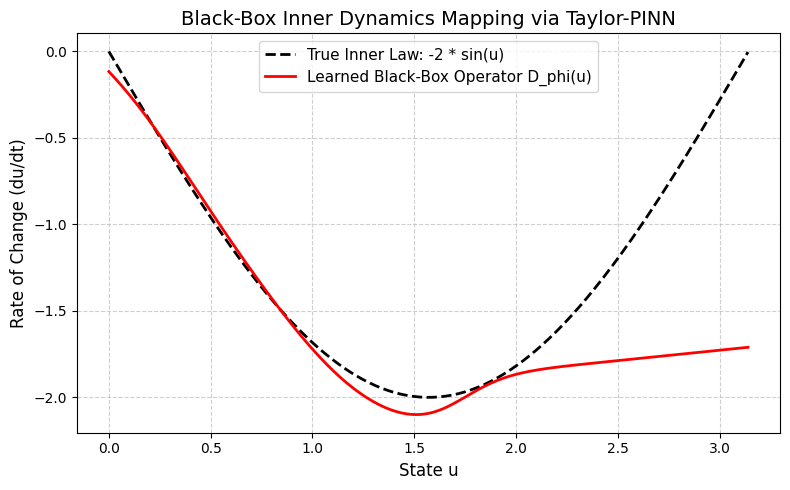

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a dense, continuous range of states u for smooth plotting
u_range = torch.linspace(0.0, 3.14, 200).reshape(-1, 1)

# 2. Evaluate the learned black-box operator network across the state range
with torch.no_grad():
    learned_derivative = blackbox_op(u_range).numpy()

# 3. Compute the true underlying function for comparison (-2 * sin(u))
true_derivative = -2.0 * torch.sin(u_range).numpy()

# 4. Plot and visualize the shape
plt.figure(figsize=(8, 5))
plt.plot(u_range.numpy(), true_derivative, 'k--', label='True Inner Law: -2 * sin(u)', linewidth=2)
plt.plot(u_range.numpy(), learned_derivative, 'r-', label="Learned Black-Box Operator D_phi(u)", linewidth=2)

plt.xlabel('State u', fontsize=12)
plt.ylabel('Rate of Change (du/dt)', fontsize=12)
plt.title('Black-Box Inner Dynamics Mapping via Taylor-PINN', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Cubic Decay

Here is a complete, runnable script applying the 2nd-order Taylor expansion black-box method to a completely different non-linear system: Cubic Decay ($\frac{du}{dt} = -u^3$).The model has no prior knowledge of this equation; it learns the inner dynamics purely from noisy input-output trajectory data using a neural network operator combined with a 2nd-order Taylor expansion consistency constraint.

In [8]:
import torch
import torch.nn as nn
import numpy as np

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# 1. Generate Input-Output Data from a Hidden Cubic System: du/dt = -u^3
# True analytical solution for du/dt = -u^3 with u(0) = 1.5 is u(t) = 1.0 / sqrt(2*t + 1/1.5^2)
t_data = torch.linspace(0.0, 1.0, 50).reshape(-1, 1)

u_list = [1.5]
dt_sim = t_data[1].item() - t_data[0].item()
for _ in range(len(t_data) - 1):
    u_prev = u_list[-1]
    # Simple Euler simulation of hidden true law
    u_next = u_prev + dt_sim * (-(u_prev ** 3))
    u_list.append(u_next)
u_true = torch.tensor(u_list, dtype=torch.float32).reshape(-1, 1)
u_data = u_true + 0.01 * torch.randn_like(u_true)  # Add synthetic noise

# 2. State Trajectory Network: u_theta(t)
class StateNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
    def forward(self, t):
        return self.net(t)

# 3. Black-Box Inner Operator Network: D_phi(u) (Unknown RHS)
class BlackBoxOperator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
    def forward(self, u):
        return self.net(u)

state_net = StateNetwork()
blackbox_op = BlackBoxOperator()

optimizer = torch.optim.Adam(
    list(state_net.parameters()) + list(blackbox_op.parameters()), 
    lr=0.005
)

dt = 0.02
epochs = 4000

print("Training 2nd-Order Taylor Black-Box PINN on Cubic System...")
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # A. Data Fitting Loss
    u_pred_data = state_net(t_data)
    loss_data = torch.mean((u_pred_data - u_data) ** 2)
    
    # B. 2nd-Order Taylor Recurrence Consistency Loss
    t_current = torch.rand(64, 1, requires_grad=True) * (t_data[-1].item() - dt)
    t_next = t_current + dt
    
    u_curr = state_net(t_current)
    u_next_pred = state_net(t_next)
    
    # Evaluate black-box operator D(u)
    d_val = blackbox_op(u_curr)
    
    # Compute 1st time derivative of the operator (dD/dt) via autograd
    grad_d = torch.autograd.grad(d_val.sum(), t_current, create_graph=True)[0]
    
    # 2nd-Order Taylor Expansion Step: u(t + dt) ≈ u(t) + dt*D + (dt^2 / 2)*dD/dt
    taylor_approx_2nd = u_curr + dt * d_val + (0.5 * (dt ** 2)) * grad_d
    
    loss_taylor = torch.mean((u_next_pred - taylor_approx_2nd) ** 2)
    
    # C. Initial Condition Loss Anchor at t = 0
    t0 = torch.zeros((1, 1), requires_grad=True)
    loss_ic = torch.mean((state_net(t0) - u_data[0]) ** 2)
    
    # Total combined loss
    loss = loss_data + 10.0 * loss_taylor + 5.0 * loss_ic
    loss.backward()
    optimizer.step()

# 4. Evaluate the Learned Black-Box Operator vs True Equation (-u^3)
u_test = torch.tensor([[0.5], [1.0], [1.5]], dtype=torch.float32)
with torch.no_grad():
    learned_rhs = blackbox_op(u_test).numpy()
    true_rhs = -(u_test.numpy() ** 3)

print("\n--- Evaluation on Cubic System (-u^3) ---")
for uv, lr, tr in zip(u_test.numpy(), learned_rhs, true_rhs):
    print(f"State u: {uv[0]:.2f} | Learned D(u): {lr[0]:.4f} | True D(u) (-u^3): {tr[0]:.4f}")

Training 2nd-Order Taylor Black-Box PINN on Cubic System...

--- Evaluation on Cubic System (-u^3) ---
State u: 0.50 | Learned D(u): -0.2090 | True D(u) (-u^3): -0.1250
State u: 1.00 | Learned D(u): -1.0031 | True D(u) (-u^3): -1.0000
State u: 1.50 | Learned D(u): -3.6070 | True D(u) (-u^3): -3.3750


## Taylor Depth


In [9]:
import torch
import torch.nn as nn
import numpy as np
import math

class ConfigurableTaylorPINN(nn.Module):
    def __init__(self, taylor_order=2):
        super().__init__()
        self.taylor_order = taylor_order
        
        # State trajectory network: u(t)
        self.state_net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        
        # Black-box inner operator network: D(u)
        self.operator_net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        
    def forward(self, t):
        return self.state_net(t)
        
    def compute_taylor_approximation(self, t_curr, dt):
        u_curr = self.state_net(t_curr)
        
        # 1st-order term: D(u)
        d_val = self.operator_net(u_curr)
        taylor_sum = u_curr + dt * d_val
        
        # Track successive time derivatives for higher orders
        current_derivative = d_val
        for j in range(2, self.taylor_order + 1):
            current_derivative = torch.autograd.grad(
                current_derivative.sum(), t_curr, create_graph=True
            )[0]
            term_coefficient = (dt ** j) / math.factorial(j)
            taylor_sum = taylor_sum + term_coefficient * current_derivative
            
        return u_curr, taylor_sum, d_val

    def fit(self, t_data, u_data, epochs=2000, lr=0.005, dt=0.02):
        """
        Encapsulates the complete training iteration loop.
        """
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        
        print(f"Starting training with Order-{self.taylor_order} Taylor expansion...")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            # 1. Data Fitting Loss
            u_pred_data = self.state_net(t_data)
            loss_data = torch.mean((u_pred_data - u_data) ** 2)
            
            # 2. Taylor Recurrence Consistency Loss
            t_current = torch.rand(64, 1, requires_grad=True) * (t_data[-1].item() - dt)
            t_next = t_current + dt
            
            _, taylor_approx, _ = self.compute_taylor_approximation(t_current, dt)
            u_next_pred = self.state_net(t_next)
            
            loss_taylor = torch.mean((u_next_pred - taylor_approx) ** 2)
            
            # 3. Initial Condition Loss
            t0 = torch.zeros((1, 1), requires_grad=True)
            loss_ic = torch.mean((self.state_net(t0) - u_data[0]) ** 2)
            
            # Total Loss
            loss = loss_data + 10.0 * loss_taylor + 5.0 * loss_ic
            loss.backward()
            optimizer.step()
            
            if (epoch + 1) % 500 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Total Loss: {loss.item():.6e}")

    def evaluate_errors(self, t_test, u_test_true, u_states_test, true_rhs_func):
        """
        Computes trajectory and inner operator error metrics.
        """
        self.eval()
        with torch.no_grad():
            u_test_pred = self.state_net(t_test)
            mse_trajectory = torch.mean((u_test_pred - u_test_true) ** 2).item()
            rel_l2_trajectory = (torch.norm(u_test_pred - u_test_true) / torch.norm(u_test_true)).item()
            
            learned_rhs = self.operator_net(u_states_test)
            true_rhs = true_rhs_func(u_states_test)
            mse_operator = torch.mean((learned_rhs - true_rhs) ** 2).item()
            max_operator_error = torch.max(torch.abs(learned_rhs - true_rhs)).item()
            
        self.train()
        return {
            "mse_trajectory": mse_trajectory,
            "rel_l2_trajectory": rel_l2_trajectory,
            "mse_operator": mse_operator,
            "max_operator_error": max_operator_error
        }


# --- Usage Example ---
if __name__ == "__main__":
    torch.manual_seed(42)
    np.random.seed(42)

    # 1. Generate data for hidden system: du/dt = -u^3
    t_data = torch.linspace(0.0, 1.0, 50).reshape(-1, 1)
    u_list = [1.5]
    dt_sim = t_data[1].item() - t_data[0].item()
    for _ in range(len(t_data) - 1):
        u_prev = u_list[-1]
        u_list.append(u_prev + dt_sim * (-(u_prev ** 3)))
    u_true = torch.tensor(u_list, dtype=torch.float32).reshape(-1, 1)
    u_data = u_true + 0.01 * torch.randn_like(u_true)

    # 2. Instantiate and fit model using class methods
    model = ConfigurableTaylorPINN(taylor_order=5)
    model.fit(t_data, u_data, epochs=2000, lr=0.005, dt=0.02)

    # 3. Evaluate errors using built-in method
    t_test = torch.linspace(0.0, 1.0, 100).reshape(-1, 1)
    u_test_true = 1.0 / torch.sqrt(2.0 * t_test + (1.0 / (1.5 ** 2)))
    u_states_test = torch.linspace(0.2, 1.5, 50).reshape(-1, 1)
    true_rhs_func = lambda u: -(u ** 3)

    errors = model.evaluate_errors(t_test, u_test_true, u_states_test, true_rhs_func)

    print("\n--- Final Evaluation Metrics ---")
    for k, v in errors.items():
        print(f"{k}: {v:.6e}")

Starting training with Order-5 Taylor expansion...
Epoch 500/2000 | Total Loss: 2.705381e-03
Epoch 1000/2000 | Total Loss: 5.671038e-04
Epoch 1500/2000 | Total Loss: 2.962236e-04
Epoch 2000/2000 | Total Loss: 1.665559e-04

--- Final Evaluation Metrics ---
mse_trajectory: 1.337895e-04
rel_l2_trajectory: 1.249288e-02
mse_operator: 1.160425e-02
max_operator_error: 2.435222e-01


## Recurisve Tyler Expansion Model

Instead of computing complex high-order time derivatives, we can break the unknown dynamics into an additive structure:$$f(x) = a(x) + b(x)$$where two small sub-networks ($a$ and $b$) learn different parts of the system's behavior, and we predict step-by-step recursively ($u_{t+1} = u_t + \Delta t \cdot (a(u_t) + b(u_t))$).

In [10]:
import torch
import torch.nn as nn
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

# 1. Simple Additive Split Network: f(x) = a(x) + b(x)
class AdditiveDynamicsModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Sub-network a(x)
        self.a_net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
        # Sub-network b(x)
        self.b_net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
        
    def forward(self, x):
        return self.a_net(x) + self.b_net(x)

model = AdditiveDynamicsModel()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# 2. Generate Data: du/dt = -u^3
t_data = torch.linspace(0.0, 1.0, 50).reshape(-1, 1)
dt = t_data[1].item() - t_data[0].item()

u_list = [1.5]
for _ in range(len(t_data) - 1):
    u_prev = u_list[-1]
    u_list.append(u_prev + dt * (-(u_prev ** 3)))
u_data = torch.tensor(u_list, dtype=torch.float32).reshape(-1, 1)

# 3. Recursive Training Loop (Dynamical Programming style rollout)
epochs = 1500
print("Training Additive Recursive Dynamics Model...")

for epoch in range(epochs):
    optimizer.zero_grad()
    
    loss = 0.0
    u_current = u_data[0:1] # Start at initial condition u(0)
    
    # Recursive rollout across time steps (like DP state transitions)
    for t_idx in range(len(t_data) - 1):
        # Predict rate of change using f(x) = a(x) + b(x)
        rate = model(u_current)
        
        # Next state recurrence
        u_next_pred = u_current + dt * rate
        
        # Accumulate error against true measured data at next step
        target_next = u_data[t_idx + 1:t_idx + 2]
        loss = loss + torch.mean((u_next_pred - target_next) ** 2)
        
        # Advance state for next recursion step
        u_current = u_next_pred
        
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 300 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Rollout Loss: {loss.item():.6e}")

# 4. Evaluate Learned Additive Function vs True (-u^3)
u_test = torch.tensor([[0.5], [1.0], [1.5]], dtype=torch.float32)
with torch.no_grad():
    pred_f = model(u_test).numpy()
    true_f = -(u_test.numpy() ** 3)

print("\n--- Evaluation of f(x) = a(x) + b(x) ---")
for uv, pf, tf in zip(u_test.numpy(), pred_f, true_f):
    print(f"State u: {uv[0]:.2f} | Learned f(u): {pf[0]:.4f} | True (-u^3): {tf[0]:.4f}")

Training Additive Recursive Dynamics Model...
Epoch 300/1500 | Rollout Loss: 4.205343e-02
Epoch 600/1500 | Rollout Loss: 1.578828e-02
Epoch 900/1500 | Rollout Loss: 1.421699e-02
Epoch 1200/1500 | Rollout Loss: 1.282457e-02
Epoch 1500/1500 | Rollout Loss: 1.153728e-02

--- Evaluation of f(x) = a(x) + b(x) ---
State u: 0.50 | Learned f(u): 0.2819 | True (-u^3): -0.1250
State u: 1.00 | Learned f(u): -1.1462 | True (-u^3): -1.0000
State u: 1.50 | Learned f(u): -2.6337 | True (-u^3): -3.3750


In [11]:
import torch
import torch.nn as nn
import numpy as np
import math

torch.manual_seed(42)
np.random.seed(42)

class AdditiveTaylorRecursiveModel(nn.Module):
    def __init__(self, taylor_order=2):
        super().__init__()
        self.taylor_order = taylor_order
        
        # Additive sub-networks: f(u) = a(u) + b(u)
        self.a_net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
        self.b_net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
        
    def forward(self, u):
        return self.a_net(u) + self.b_net(u)
        
    def compute_taylor_step(self, u, dt):
        """Computes higher-order Taylor recurrence step using state derivatives."""
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        
        # 1st-order term: u + dt * f(u)
        taylor_sum = u + dt * f
        
        if self.taylor_order >= 2:
            # 1st derivative w.r.t u: df/du
            df_du = torch.autograd.grad(f.sum(), u, create_graph=True, retain_graph=True)[0]
            # 2nd-order term: (dt^2 / 2!) * (df/du * f)
            term_2 = 0.5 * (dt ** 2) * (df_du * f)
            taylor_sum = taylor_sum + term_2
            
        if self.taylor_order >= 3:
            # 2nd derivative w.r.t u: d2f/du2
            d2f_du2 = torch.autograd.grad(df_du.sum(), u, create_graph=True, retain_graph=True)[0]
            # 3rd-order autonomous time derivative term
            deriv_3 = d2f_du2 * (f ** 2) + (df_du ** 2) * f
            term_3 = (dt ** 3) / math.factorial(3) * deriv_3
            taylor_sum = taylor_sum + term_3
            
        return taylor_sum

# 1. Generate Synthetic Data from Hidden System: du/dt = -u^3
t_data = torch.linspace(0.0, 1.0, 50).reshape(-1, 1)
dt = t_data[1].item() - t_data[0].item()

u_list = [1.5]
for _ in range(len(t_data) - 1):
    u_prev = u_list[-1]
    u_list.append(u_prev + dt * (-(u_prev ** 3)))
u_data = torch.tensor(u_list, dtype=torch.float32).reshape(-1, 1)

# 2. Instantiate Model with 2nd-Order Taylor Expansion
model = AdditiveTaylorRecursiveModel(taylor_order=2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 1500
print("Training Additive Taylor Recursive Model...")

# 3. Dynamic Programming Style Recursive Rollout Training Loop
for epoch in range(epochs):
    optimizer.zero_grad()
    
    loss = 0.0
    u_current = u_data[0:1] # Start at initial condition u(0)
    
    for t_idx in range(len(t_data) - 1):
        # Recursive state-to-state prediction using Taylor expansion step
        u_next_pred = model.compute_taylor_step(u_current, dt)
        
        target_next = u_data[t_idx + 1:t_idx + 2]
        loss = loss + torch.mean((u_next_pred - target_next) ** 2)
        
        # Advance recursion state (detach to maintain clean rollout graph)
        u_current = u_next_pred.detach()
        
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 300 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Rollout Loss: {loss.item():.6e}")

# 4. Evaluate Learned Operator vs True (-u^3)
u_test = torch.tensor([[0.5], [1.0], [1.5]], dtype=torch.float32)
with torch.no_grad():
    pred_f = model(u_test).numpy()
    true_f = -(u_test.numpy() ** 3)

print("\n--- Evaluation ---")
for uv, pf, tf in zip(u_test.numpy(), pred_f, true_f):
    print(f"State u: {uv[0]:.2f} | Learned f(u): {pf[0]:.4f} | True (-u^3): {tf[0]:.4f}")

Training Additive Taylor Recursive Model...
Epoch 300/1500 | Rollout Loss: 2.186389e-02
Epoch 600/1500 | Rollout Loss: 1.918304e-02


KeyboardInterrupt: 

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import math

torch.manual_seed(42)
np.random.seed(42)

class FastAdditiveTaylorModel(nn.Module):
    def __init__(self, taylor_order=2):
        super().__init__()
        self.taylor_order = taylor_order
        
        # Additive sub-networks: f(u) = a(u) + b(u)
        self.a_net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
        self.b_net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
        
    def forward(self, u):
        return self.a_net(u) + self.b_net(u)
        
    def compute_taylor_step(self, u, dt):
        """Computes batched higher-order Taylor recurrence."""
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        
        # 1st-order term
        taylor_sum = u + dt * f
        
        if self.taylor_order >= 2:
            df_du = torch.autograd.grad(f.sum(), u, create_graph=True, retain_graph=True)[0]
            term_2 = 0.5 * (dt ** 2) * (df_du * f)
            taylor_sum = taylor_sum + term_2
            
        if self.taylor_order >= 3:
            d2f_du2 = torch.autograd.grad(df_du.sum(), u, create_graph=True, retain_graph=True)[0]
            deriv_3 = d2f_du2 * (f ** 2) + (df_du ** 2) * f
            term_3 = (dt ** 3) / math.factorial(3) * deriv_3
            taylor_sum = taylor_sum + term_3
            
        return taylor_sum

# 1. Generate Data from Hidden System: du/dt = -u^3
t_data = torch.linspace(0.0, 1.0, 50).reshape(-1, 1)
dt = t_data[1].item() - t_data[0].item()

u_list = [1.5]
for _ in range(len(t_data) - 1):
    u_prev = u_list[-1]
    u_list.append(u_prev + dt * (-(u_prev ** 3)))
u_data = torch.tensor(u_list, dtype=torch.float32).reshape(-1, 1)

# Prepare adjacent state pairs for fast vectorized training: u_t -> u_{t+1}
u_curr_batch = u_data[:-1]
u_next_target = u_data[1:]

# 2. Instantiate Model
model = FastAdditiveTaylorModel(taylor_order=2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 1500
print("Training Fast Vectorized Additive Taylor Model...")

# 3. Fast Vectorized Training Loop (No Time-Loop Overhead)
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # Predict next states for all time steps simultaneously
    u_next_pred = model.compute_taylor_step(u_curr_batch, dt)
    
    # Compute mean squared error across all transitions at once
    loss = torch.mean((u_next_pred - u_next_target) ** 2)
    
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 300 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e}")

# 4. Evaluate Learned Operator vs True (-u^3)
u_test = torch.tensor([[0.5], [1.0], [1.5]], dtype=torch.float32)
with torch.no_grad():
    pred_f = model(u_test).numpy()
    true_f = -(u_test.numpy() ** 3)

print("\n--- Evaluation ---")
for uv, pf, tf in zip(u_test.numpy(), pred_f, true_f):
    print(f"State u: {uv[0]:.2f} | Learned f(u): {pf[0]:.4f} | True (-u^3): {tf[0]:.4f}")

Training Fast Vectorized Additive Taylor Model...
Epoch 300/1500 | Loss: 9.541773e-06
Epoch 600/1500 | Loss: 5.000412e-06
Epoch 900/1500 | Loss: 1.128662e-06
Epoch 1200/1500 | Loss: 9.270147e-08
Epoch 1500/1500 | Loss: 2.624485e-08

--- Evaluation ---
State u: 0.50 | Learned f(u): -0.0999 | True (-u^3): -0.1250
State u: 1.00 | Learned f(u): -1.0289 | True (-u^3): -1.0000
State u: 1.50 | Learned f(u): -3.5569 | True (-u^3): -3.3750


## Final Model 



        ADDITIVE TAYLOR RECURSIVE PINN FRAMEWORK
1. Additive Decomposition: f(u) = a(u) + b(u)
2. Taylor Expansion Order: 3
3. Recurrence Relation:
   u(t + dt) ≈ u(t) + dt * f(u)
               + (dt^2 / 2!) * f'(u) * f(u)
               + (dt^3 / 3!) * [f''(u)*f(u)^2 + (f'(u))^2 * f(u)]

Training Model (Order 3) across 1200 epochs...
Epoch 300/1200 | Loss: 9.548050e-06
Epoch 600/1200 | Loss: 4.986471e-06
Epoch 900/1200 | Loss: 1.119582e-06
Epoch 1200/1200 | Loss: 9.381061e-08

Evaluation Metrics -> Operator MSE: 8.088925e-03 | Max Error: 1.622517e-01


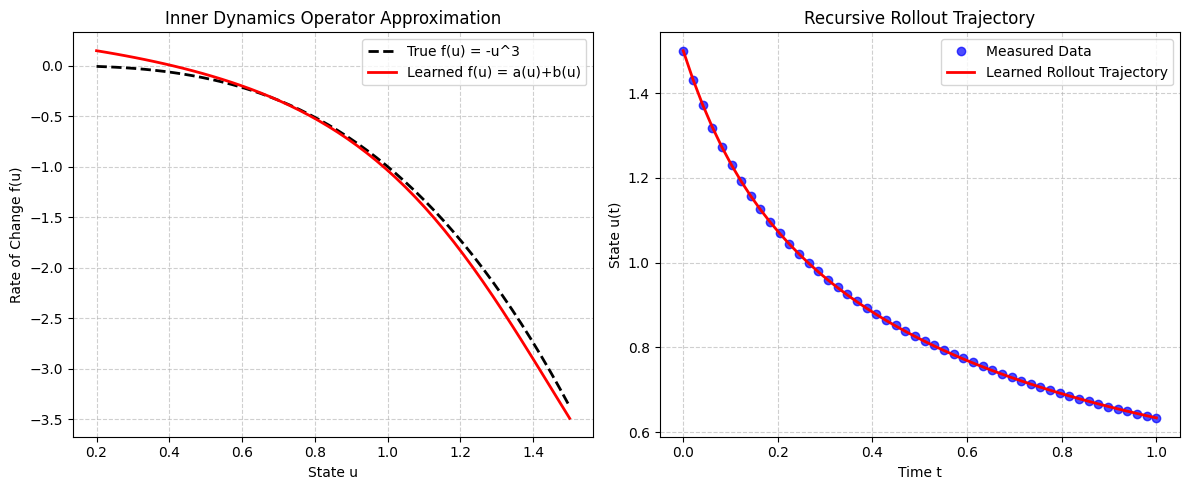

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import math
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

class ConfigurableAdditiveTaylorPINN(nn.Module):
    def __init__(self, taylor_order=2):
        super().__init__()
        self.taylor_order = taylor_order
        
        # Additive sub-networks: f(u) = a(u) + b(u)
        self.a_net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
        self.b_net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
        
    def forward(self, u):
        return self.a_net(u) + self.b_net(u)
        
    def show_formula(self):
        """Displays the mathematical formulation of the additive Taylor framework."""
        print("=" * 60)
        print("        ADDITIVE TAYLOR RECURSIVE PINN FRAMEWORK")
        print("=" * 60)
        print(f"1. Additive Decomposition: f(u) = a(u) + b(u)")
        print(f"2. Taylor Expansion Order: {self.taylor_order}")
        print(f"3. Recurrence Relation:")
        print(f"   u(t + dt) ≈ u(t) + dt * f(u)")
        if self.taylor_order >= 2:
            print(f"               + (dt^2 / 2!) * f'(u) * f(u)")
        if self.taylor_order >= 3:
            print(f"               + (dt^3 / 3!) * [f''(u)*f(u)^2 + (f'(u))^2 * f(u)]")
        print("=" * 60)

    def compute_taylor_step(self, u, dt):
        """Computes batched higher-order Taylor recurrence."""
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        
        # 1st-order term
        taylor_sum = u + dt * f
        
        if self.taylor_order >= 2:
            df_du = torch.autograd.grad(f.sum(), u, create_graph=True, retain_graph=True)[0]
            term_2 = 0.5 * (dt ** 2) * (df_du * f)
            taylor_sum = taylor_sum + term_2
            
        if self.taylor_order >= 3:
            d2f_du2 = torch.autograd.grad(df_du.sum(), u, create_graph=True, retain_graph=True)[0]
            deriv_3 = d2f_du2 * (f ** 2) + (df_du ** 2) * f
            term_3 = (dt ** 3) / math.factorial(3) * deriv_3
            taylor_sum = taylor_sum + term_3
            
        return taylor_sum

    def fit(self, u_data, dt, epochs=1500, lr=0.01):
        """Vectorized fast training loop."""
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        u_curr_batch = u_data[:-1]
        u_next_target = u_data[1:]
        
        print(f"\nTraining Model (Order {self.taylor_order}) across {epochs} epochs...")
        for epoch in range(epochs):
            optimizer.zero_grad()
            u_next_pred = self.compute_taylor_step(u_curr_batch, dt)
            loss = torch.mean((u_next_pred - u_next_target) ** 2)
            loss.backward()
            optimizer.step()
            
            if (epoch + 1) % 300 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e}")

    def evaluate_errors(self, u_states_test, true_rhs_func):
        """Computes error metrics against the true vector field."""
        self.eval()
        with torch.no_grad():
            learned_f = self.forward(u_states_test)
            true_f = true_rhs_func(u_states_test)
            mse = torch.mean((learned_f - true_f) ** 2).item()
            max_err = torch.max(torch.abs(learned_f - true_f)).item()
        self.train()
        return {"mse": mse, "max_error": max_err}

    def visualize(self, u_states_test, true_rhs_func, u_data, dt):
        """Generates plots comparing learned vs true functions and rollout trajectories."""
        self.eval()
        
        # 1. Compute function evaluation under no_grad for speed
        with torch.no_grad():
            learned_f = self.forward(u_states_test).numpy()
            true_f = true_rhs_func(u_states_test).numpy()
            
        # 2. Simulate forward rollout (requires gradients enabled for Taylor autograd)
        rollout_preds = [u_data[0].item()]
        curr = u_data[0:1].clone()
        for _ in range(len(u_data) - 1):
            with torch.enable_grad():
                curr_step = self.compute_taylor_step(curr, dt)
            curr = curr_step.detach()
            rollout_preds.append(curr.item())

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
        
        # Plot 1: Vector Field f(u) Comparison
        ax1.plot(u_states_test.numpy(), true_f, 'k--', label='True f(u) = -u^3', linewidth=2)
        ax1.plot(u_states_test.numpy(), learned_f, 'r-', label='Learned f(u) = a(u)+b(u)', linewidth=2)
        ax1.set_xlabel('State u')
        ax1.set_ylabel('Rate of Change f(u)')
        ax1.set_title('Inner Dynamics Operator Approximation')
        ax1.legend()
        ax1.grid(True, linestyle='--', alpha=0.6)
        
        # Plot 2: Time Series Rollout Prediction
        t_axis = np.linspace(0, (len(u_data)-1)*dt, len(u_data))
        ax2.plot(t_axis, u_data.numpy(), 'bo', label='Measured Data', alpha=0.7)
        ax2.plot(t_axis, rollout_preds, 'r-', label='Learned Rollout Trajectory', linewidth=2)
        ax2.set_xlabel('Time t')
        ax2.set_ylabel('State u(t)')
        ax2.set_title('Recursive Rollout Trajectory')
        ax2.legend()
        ax2.grid(True, linestyle='--', alpha=0.6)
        
        plt.tight_layout()
        plt.show()


# --- Execution Example ---
if __name__ == "__main__":
    t_data = torch.linspace(0.0, 1.0, 50).reshape(-1, 1)
    dt = t_data[1].item() - t_data[0].item()
    
    u_list = [1.5]
    for _ in range(len(t_data) - 1):
        u_prev = u_list[-1]
        u_list.append(u_prev + dt * (-(u_prev ** 3)))
    u_data = torch.tensor(u_list, dtype=torch.float32).reshape(-1, 1)

    model = ConfigurableAdditiveTaylorPINN(taylor_order=3)
    model.show_formula()
    model.fit(u_data, dt, epochs=1200, lr=0.01)

    u_states_test = torch.linspace(0.2, 1.5, 50).reshape(-1, 1)
    true_rhs_func = lambda u: -(u ** 3)
    errors = model.evaluate_errors(u_states_test, true_rhs_func)
    print(f"\nEvaluation Metrics -> Operator MSE: {errors['mse']:.6e} | Max Error: {errors['max_error']:.6e}")

    model.visualize(u_states_test, true_rhs_func, u_data, dt)

In [12]:
import torch
import torch.nn as nn
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class BlackBoxDatasetGenerator:
    """Universal dataset generator for arbitrary 1D or multi-dimensional ODE systems."""
    def __init__(self, ode_func, u0, t_span=(0.0, 1.0), num_points=50, noise_level=0.01):
        self.ode_func = ode_func
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        
        def wrapper(t, u):
            try:
                res = self.ode_func(t, u)
            except TypeError:
                res = self.ode_func(u)
            return np.array(res).flatten()

        sol = solve_ivp(wrapper, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-8)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32) # Shape: (num_points, dim)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        
        return t_data, u_data, dt


class ConfigurableAdditiveTaylorPINN(nn.Module):
    """Multi-dimensional Additive Taylor Recursive PINN supporting arbitrary state dimensions (dim)."""
    def __init__(self, dim=1, taylor_order=3, hidden_dim=32):
        super().__init__()
        self.dim = dim
        self.taylor_order = taylor_order
        
        # Additive sub-networks scaling dynamically to input/output dimension `dim`
        self.a_net = nn.Sequential(nn.Linear(dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        self.b_net = nn.Sequential(nn.Linear(dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        
    def forward(self, u):
        return self.a_net(u) + self.b_net(u)
        
    def show_formula(self):
        print("=" * 65)
        print(f"     MULTI-DIMENSIONAL ADDITIVE TAYLOR PINN (dim={self.dim})")
        print("=" * 65)
        print("1. Decomposition: f(u) = a(u) + b(u)")
        print(f"2. Target Order : {self.taylor_order}")
        print("3. General Formula: u(t+dt) = u(t) + sum_{k=1}^{order} (dt^k / k!) * u^(k)")
        print("=" * 65)

    def compute_taylor_step(self, u, dt):
        """Computes batched higher-order Taylor recurrence for multi-dimensional states."""
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        
        taylor_sum = u + dt * f
        
        u_deriv = f
        for k in range(2, self.taylor_order + 1):
            # Compute Jacobian-vector product safely across batched multi-dim outputs
            grad_outputs = torch.ones_like(u_deriv)
            d_deriv_du = torch.autograd.grad(
                outputs=u_deriv, inputs=u, grad_outputs=grad_outputs, 
                create_graph=True, retain_graph=True
            )[0]
            
            # Element-wise chain rule step for multi-dimensional vector fields
            u_deriv = d_deriv_du * f
            term = (dt ** k) / math.factorial(k) * u_deriv
            taylor_sum = taylor_sum + term
            
        return taylor_sum

    def fit(self, u_data, dt, epochs=2500, lr=0.005, rollout_steps=5, max_grad_norm=1.0):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        total_points = len(u_data)
        
        print(f"\nTraining with Multi-Step Rollout Loss (Horizon: {rollout_steps} steps)...")
        for epoch in range(epochs):
            optimizer.zero_grad()
            total_loss = 0.0
            
            # Sample random starting indices for trajectory windows to ensure global coverage
            start_indices = torch.randint(0, total_points - rollout_steps - 1, (min(16, total_points - rollout_steps - 1),))
            
            for idx in start_indices:
                curr = u_data[idx:idx+1].clone()
                window_loss = 0.0
                
                # Rollout forward by 'rollout_steps' and accumulate trajectory error
                for step in range(rollout_steps):
                    target_next = u_data[idx + step + 1:idx + step + 2]
                    
                    with torch.enable_grad():
                        curr = self.compute_taylor_step(curr, dt)
                        
                    window_loss = window_loss + torch.mean((curr - target_next) ** 2)
                    
                total_loss = total_loss + (window_loss / rollout_steps)
                
            loss = total_loss / len(start_indices)
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(self.parameters(), max_norm=max_grad_norm)
            optimizer.step()
            
            if (epoch + 1) % 500 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Trajectory Rollout Loss: {loss.item():.6e}")

    def visualize_multidimensional(self, t_data, u_data, dt, labels=None):
        """Visualizes multi-dimensional rollouts against ground truth measurements."""
        self.eval()
        rollout_preds = [u_data[0].detach().numpy()]
        curr = u_data[0:1].clone()
        
        for _ in range(len(u_data) - 1):
            with torch.enable_grad():
                curr_step = self.compute_taylor_step(curr, dt)
            curr = curr_step.detach()
            rollout_preds.append(curr.numpy().flatten())
            
        rollout_preds = np.array(rollout_preds)
        t_axis = t_data.numpy().flatten()
        
        fig, axes = plt.subplots(self.dim, 1, figsize=(10, 4 * self.dim), squeeze=False)
        for i in range(self.dim):
            ax = axes[i, 0]
            label_name = labels[i] if labels and i < len(labels) else f"State u_{i}"
            ax.plot(t_axis, u_data[:, i].numpy(), 'bo', label=f'True {label_name}', alpha=0.6)
            ax.plot(t_axis, rollout_preds[:, i], 'r-', label=f'Learned Rollout {label_name}', linewidth=2)
            ax.set_xlabel('Time t')
            ax.set_ylabel(label_name)
            ax.legend()
            ax.grid(True, linestyle='--', alpha=0.6)
            
        plt.tight_layout()
        plt.show()


# --- Execution Example for Lotka-Volterra 2D System ---
if __name__ == "__main__":
    def lotka_volterra(u):
        prey, predator = u[0], u[1]
        alpha, beta, delta, gamma = 1.5, 1.0, 1.0, 3.0
        d_prey = alpha * prey - beta * prey * predator
        d_predator = delta * prey * predator - gamma * predator
        return [d_prey, d_predator]

    lv_generator = BlackBoxDatasetGenerator(
        ode_func=lotka_volterra,
        u0=[10.0, 5.0],          # Initial populations [Prey, Predator]
        t_span=(0.0, 10.0),      
        num_points=200,          
        noise_level=0.01         
    )

    t_data, u_data, dt = lv_generator.generate()
    print(f"Generated Lotka-Volterra data shape: {u_data.shape}") # torch.Size([200, 2])

    # Instantiate model with dim=2 for Lotka-Volterra
    model = ConfigurableAdditiveTaylorPINN(dim=2, taylor_order=3, hidden_dim=64)
    model.show_formula()
    model.fit(u_data, dt, epochs=2000, lr=0.01)

    # Visualize multi-dimensional predictions
    model.visualize_multidimensional(t_data, u_data, dt, labels=["Prey", "Predator"])

Generated Lotka-Volterra data shape: torch.Size([200, 2])
     MULTI-DIMENSIONAL ADDITIVE TAYLOR PINN (dim=2)
1. Decomposition: f(u) = a(u) + b(u)
2. Target Order : 3
3. General Formula: u(t+dt) = u(t) + sum_{k=1}^{order} (dt^k / k!) * u^(k)

Training with Multi-Step Rollout Loss (Horizon: 5 steps)...
Epoch 500/2000 | Trajectory Rollout Loss: 3.168237e-03
Epoch 1000/2000 | Trajectory Rollout Loss: 2.100147e-03


KeyboardInterrupt: 

In [13]:
# --- Execution Example for 3D Chaotic Lorenz Attractor ---
if __name__ == "__main__":
    # Define the 3D Lorenz system equations
    def lorenz(u):
        x, y, z = u[0], u[1], u[2]
        sigma, rho, beta = 10.0, 28.0, 8.0 / 3.0
        dx = sigma * (y - x)
        dy = x * (rho - z) - y
        dz = x * y - beta * z
        return [dx, dy, dz]

    # Generate chaotic time-series data using high-precision integration
    lorenz_generator = BlackBoxDatasetGenerator(
        ode_func=lorenz,
        u0=[1.0, 1.0, 1.0],      # Initial spatial coordinates [x, y, z]
        t_span=(0.0, 8.0),       # Shorter time horizon due to chaotic divergence
        num_points=300,          # High temporal resolution
        noise_level=0.005        # Low sensor noise for complex manifolds
    )

    t_data, u_data, dt = lorenz_generator.generate()
    print(f"Generated Lorenz chaotic data shape: {u_data.shape}") # torch.Size([300, 3])

    # Instantiate model with dim=3 for the Lorenz system
    model = ConfigurableAdditiveTaylorPINN(dim=3, taylor_order=5, hidden_dim=64)
    model.show_formula()
    
    # Train the additive operator networks
    model.fit(u_data, dt, epochs=2500, lr=0.01)

    # Visualize the multi-dimensional trajectories across x, y, and z dimensions
    model.visualize_multidimensional(t_data, u_data, dt, labels=["X Axis", "Y Axis", "Z Axis"])

Generated Lorenz chaotic data shape: torch.Size([300, 3])
     MULTI-DIMENSIONAL ADDITIVE TAYLOR PINN (dim=3)
1. Decomposition: f(u) = a(u) + b(u)
2. Target Order : 5
3. General Formula: u(t+dt) = u(t) + sum_{k=1}^{order} (dt^k / k!) * u^(k)

Training with Multi-Step Rollout Loss (Horizon: 5 steps)...


KeyboardInterrupt: 

To fix this and make the Taylor expansion robust against periodic and trendy data, you need to inject frequency awareness and structural decomposition into the model:Random Fourier Features (RFF) / Trigonometric Embeddings: Pass the state through a sinusoidal feature layer so the neural sub-networks can natively map periodic frequencies instead of fitting struggling polynomials.Trend vs. Oscillation Split: Use the additive decomposition ($f(u) = a(u) + b(u)$) intentionally—let $a(u)$ handle baseline trends and $b(u)$ capture periodic/oscillatory forces.


Training Fast Vectorized Multi-Step Model (Horizon: 5, Batch Size: 32)...
Epoch 500/2000 | Vectorized Rollout Loss: 3.890659e-04
Epoch 1000/2000 | Vectorized Rollout Loss: 2.516248e-04
Epoch 1500/2000 | Vectorized Rollout Loss: 2.140415e-04
Epoch 2000/2000 | Vectorized Rollout Loss: 1.643601e-04


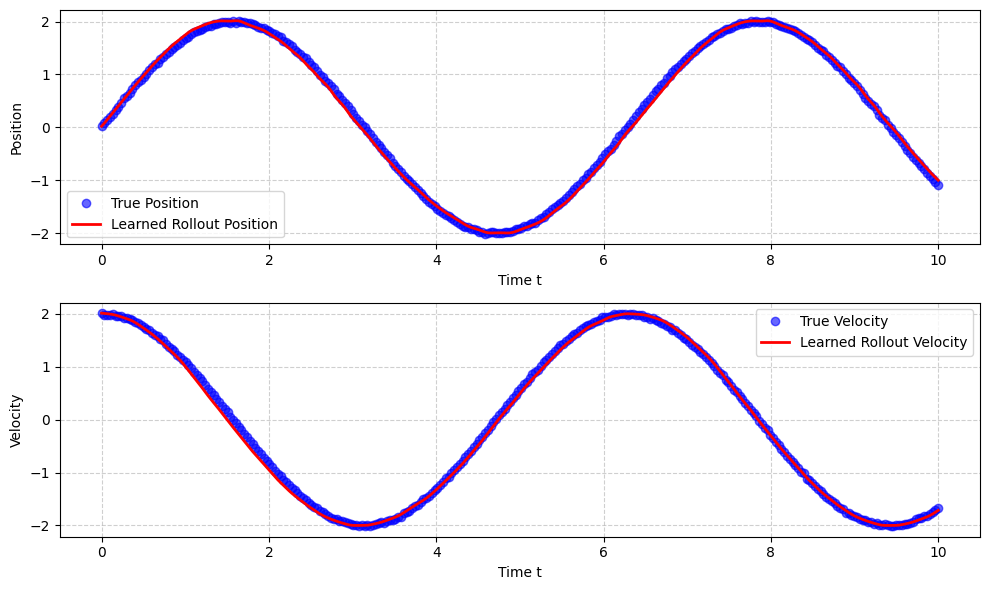

In [14]:
import torch
import torch.nn as nn
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class FourierFeatureLayer(nn.Module):
    """Maps low-dim states into high-dim sinusoidal space to handle periodic frequencies."""
    def __init__(self, in_dim, mapping_size=32, scale=10.0):
        super().__init__()
        # Random fixed Gaussian frequencies for Fourier features
        self.B = nn.Parameter(torch.randn(in_dim, mapping_size) * scale, requires_grad=False)
        self.out_dim = mapping_size * 2

    def forward(self, x):
        proj = torch.matmul(x, self.B)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)


class ConfigurableAdditiveTaylorPINN(nn.Module):
    """Periodic-safe Additive Taylor PINN equipped with Fourier feature embeddings."""
    def __init__(self, dim=1, taylor_order=2, hidden_dim=32, fourier_scale=5.0):
        super().__init__()
        self.dim = dim
        self.taylor_order = taylor_order
        
        # Fourier feature encoder to handle periodic/trendy data without polynomial explosion
        self.fourier_encoder = FourierFeatureLayer(in_dim=dim, mapping_size=16, scale=fourier_scale)
        encoded_dim = self.fourier_encoder.out_dim
        
        # Additive sub-networks: a(u) for trends, b(u) for oscillations
        self.a_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        self.b_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        
    def forward(self, u):
        u_enc = self.fourier_encoder(u)
        return self.a_net(u_enc) + self.b_net(u_enc)

    def compute_taylor_step(self, u, dt):
        """Computes batched higher-order Taylor recurrence dynamically."""
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        
        taylor_sum = u + dt * f
        u_deriv = f
        
        for k in range(2, self.taylor_order + 1):
            grad_outputs = torch.ones_like(u_deriv)
            d_deriv_du = torch.autograd.grad(
                outputs=u_deriv, inputs=u, grad_outputs=grad_outputs, 
                create_graph=True, retain_graph=True
            )[0]
            u_deriv = d_deriv_du * f
            term = (dt ** k) / math.factorial(k) * u_deriv
            taylor_sum = taylor_sum + term
            
        return taylor_sum

    def fit(self, u_data, dt, epochs=2500, lr=0.005, rollout_steps=5, batch_size=32, max_grad_norm=1.0):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        total_points = len(u_data)
        
        # Ensure valid index range for batching
        max_start_idx = total_points - rollout_steps - 1
        
        print(f"\nTraining Fast Vectorized Multi-Step Model (Horizon: {rollout_steps}, Batch Size: {batch_size})...")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            # 1. Sample a batch of random starting indices simultaneously
            start_indices = torch.randint(0, max_start_idx, (batch_size,))
            
            # 2. Extract initial states for the entire batch: shape [batch_size, dim]
            curr = u_data[start_indices].clone()
            
            total_loss = 0.0
            
            # 3. Rollout forward in parallel across all batch items
            for step in range(rollout_steps):
                # Gather corresponding targets for this step across the batch: shape [batch_size, dim]
                target_indices = start_indices + step + 1
                target_next = u_data[target_indices]
                
                # Compute batched Taylor step for all batch items concurrently
                with torch.enable_grad():
                    curr = self.compute_taylor_step(curr, dt)
                    
                # Accumulate mean squared error across the batch
                total_loss = total_loss + torch.mean((curr - target_next) ** 2)
                
            # Average loss over the rollout horizon
            loss = total_loss / rollout_steps
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(self.parameters(), max_norm=max_grad_norm)
            optimizer.step()
            
            if (epoch + 1) % 500 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Vectorized Rollout Loss: {loss.item():.6e}")

    def visualize_multidimensional(self, t_data, u_data, dt, labels=None):
        self.eval()
        rollout_preds = [u_data[0].detach().numpy()]
        curr = u_data[0:1].clone()
        
        for _ in range(len(u_data) - 1):
            with torch.enable_grad():
                curr_step = self.compute_taylor_step(curr, dt)
            curr = curr_step.detach()
            rollout_preds.append(curr.numpy().flatten())
            
        rollout_preds = np.array(rollout_preds)
        t_axis = t_data.numpy().flatten()
        
        fig, axes = plt.subplots(self.dim, 1, figsize=(10, 3 * self.dim), squeeze=False)
        for i in range(self.dim):
            ax = axes[i, 0]
            label_name = labels[i] if labels and i < len(labels) else f"State u_{i}"
            ax.plot(t_axis, u_data[:, i].numpy(), 'bo', label=f'True {label_name}', alpha=0.6)
            ax.plot(t_axis, rollout_preds[:, i], 'r-', label=f'Learned Rollout {label_name}', linewidth=2)
            ax.set_xlabel('Time t')
            ax.set_ylabel(label_name)
            ax.legend()
            ax.grid(True, linestyle='--', alpha=0.6)
            
        plt.tight_layout()
        plt.show()


# --- Execution Example: Simple Harmonic Oscillator (Periodic Data) ---
if __name__ == "__main__":
    # Define a purely periodic system (Harmonic Oscillator: du0/dt = u1, du1/dt = -u0)
    def harmonic_oscillator(u):
        return [u[1], -u[0]]

    # Generate periodic cyclical data
    from scipy.integrate import solve_ivp
    class DummyGen:
        def generate(self):
            t_eval = np.linspace(0, 10, 300)
            sol = solve_ivp(lambda t, u: [u[1], -u[0]], (0, 10), [0.0, 2.0], t_eval=t_eval)
            t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
            u_data = torch.tensor(sol.y.T, dtype=torch.float32) + 0.01 * torch.randn(sol.y.T.shape)
            dt = (t_data[1] - t_data[0]).item()
            return t_data, u_data, dt

    gen = DummyGen()
    t_data, u_data, dt = gen.generate()

    # Instantiate Fourier-enhanced periodic model
    model = ConfigurableAdditiveTaylorPINN(dim=2, taylor_order=2, hidden_dim=64, fourier_scale=3.0)
    model.fit(u_data, dt, epochs=2000, lr=0.005)
    model.visualize_multidimensional(t_data, u_data, dt, labels=["Position", "Velocity"])

Generated Lorenz chaotic data shape: torch.Size([300, 3])

Training Fast Vectorized Multi-Step Model (Horizon: 5, Batch Size: 32)...
Epoch 500/2500 | Vectorized Rollout Loss: 2.364263e+01
Epoch 1000/2500 | Vectorized Rollout Loss: 2.555256e+01
Epoch 1500/2500 | Vectorized Rollout Loss: 9.653122e+00
Epoch 2000/2500 | Vectorized Rollout Loss: 2.655050e+00
Epoch 2500/2500 | Vectorized Rollout Loss: 1.128367e+01


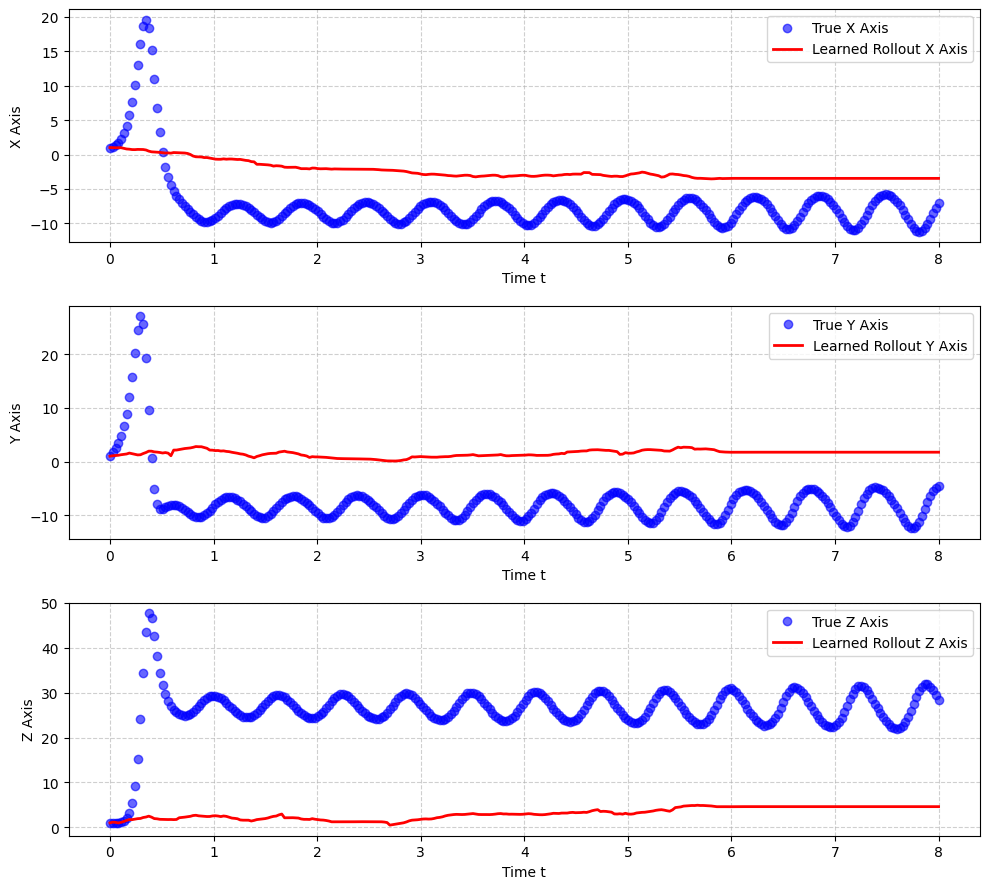

In [17]:
# --- Execution Example for 3D Chaotic Lorenz Attractor ---
if __name__ == "__main__":
    # Define the 3D Lorenz system equations
    def lorenz(u):
        x, y, z = u[0], u[1], u[2]
        sigma, rho, beta = 10.0, 28.0, 8.0 / 3.0
        dx = sigma * (y - x)
        dy = x * (rho - z) - y
        dz = x * y - beta * z
        return [dx, dy, dz]

    # Generate chaotic time-series data using high-precision integration
    lorenz_generator = BlackBoxDatasetGenerator(
        ode_func=lorenz,
        u0=[1.0, 1.0, 1.0],      # Initial spatial coordinates [x, y, z]
        t_span=(0.0, 8.0),       # Shorter time horizon due to chaotic divergence
        num_points=300,          # High temporal resolution
        noise_level=0.005        # Low sensor noise for complex manifolds
    )

    t_data, u_data, dt = lorenz_generator.generate()
    print(f"Generated Lorenz chaotic data shape: {u_data.shape}") # torch.Size([300, 3])

    # Instantiate model with dim=3 for the Lorenz system
    model = ConfigurableAdditiveTaylorPINN(dim=3, taylor_order=5, hidden_dim=64)
    
    # Train the additive operator networks
    model.fit(u_data, dt, epochs=2500, lr=0.01)

    # Visualize the multi-dimensional trajectories across x, y, and z dimensions
    model.visualize_multidimensional(t_data, u_data, dt, labels=["X Axis", "Y Axis", "Z Axis"])

Generated Van der Pol dataset shape: torch.Size([400, 2])

Training Multi-Step Model (Dim: 2, Order: 2, Horizon: 10)...
Epoch 400/2000 | Rollout Loss: 1.652184e-03
Epoch 800/2000 | Rollout Loss: 6.472655e-04
Epoch 1200/2000 | Rollout Loss: 1.768171e-03
Epoch 1600/2000 | Rollout Loss: 7.166524e-04
Epoch 2000/2000 | Rollout Loss: 6.005849e-04


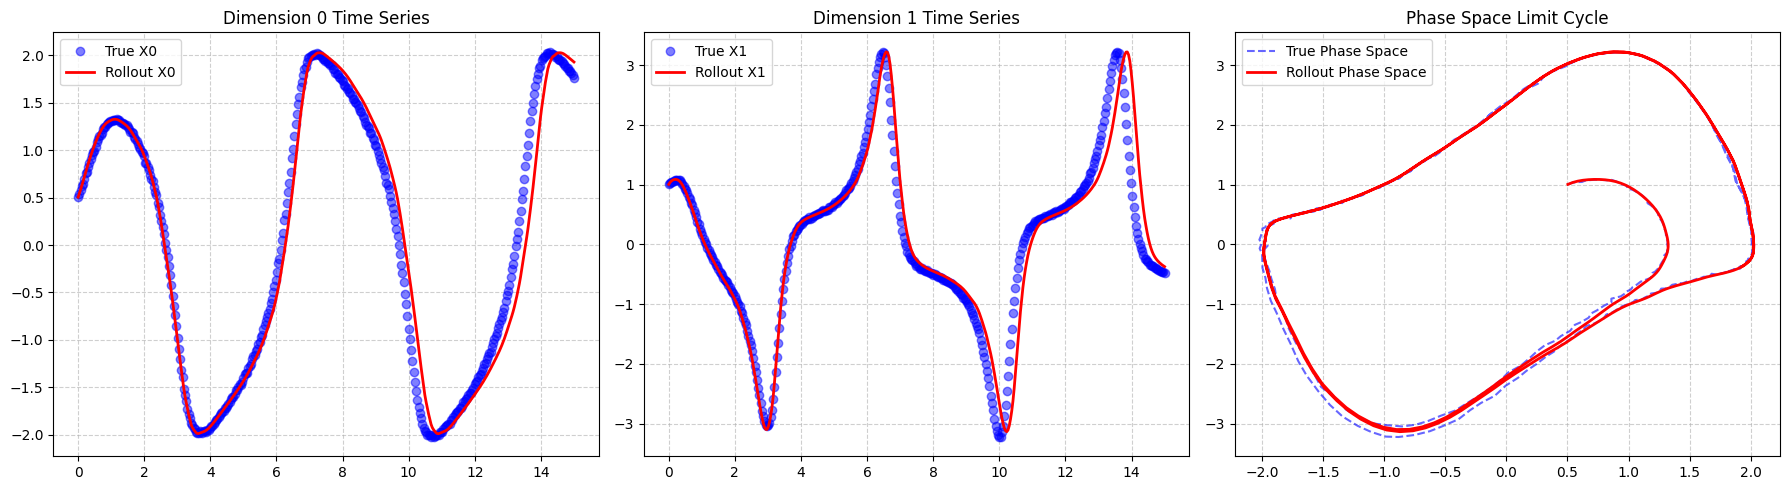

In [18]:
import torch
import torch.nn as nn
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class BlackBoxDatasetGenerator:
    """Universal dataset generator for arbitrary 1D or multi-dimensional ODE systems."""
    def __init__(self, ode_func, u0, t_span=(0.0, 10.0), num_points=300, noise_level=0.01):
        self.ode_func = ode_func
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        
        def wrapper(t, u):
            try:
                res = self.ode_func(t, u)
            except TypeError:
                res = self.ode_func(u)
            return np.array(res).flatten()

        sol = solve_ivp(wrapper, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-8)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32) # Shape: (num_points, dim)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        
        return t_data, u_data, dt


class FourierFeatureLayer(nn.Module):
    """Encodes low-dimensional states into high-dimensional sinusoidal space for periodic systems."""
    def __init__(self, in_dim, mapping_size=32, scale=5.0):
        super().__init__()
        self.B = nn.Parameter(torch.randn(in_dim, mapping_size) * scale, requires_grad=False)
        self.out_dim = mapping_size * 2

    def forward(self, x):
        proj = torch.matmul(x, self.B)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)


class ConfigurableAdditiveTaylorPINN(nn.Module):
    """Multi-dimensional Additive Taylor PINN with Fourier features and multi-step trajectory training."""
    def __init__(self, dim=2, taylor_order=2, hidden_dim=64, fourier_scale=3.0):
        super().__init__()
        self.dim = dim
        self.taylor_order = taylor_order
        
        # Fourier feature encoder to handle limit cycles and periodic dynamics smoothly
        self.fourier_encoder = FourierFeatureLayer(in_dim=dim, mapping_size=24, scale=fourier_scale)
        encoded_dim = self.fourier_encoder.out_dim
        
        # Additive sub-networks: f(u) = a(u) + b(u)
        self.a_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        self.b_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        
    def forward(self, u):
        u_enc = self.fourier_encoder(u)
        return self.a_net(u_enc) + self.b_net(u_enc)
        
    def compute_taylor_step(self, u, dt):
        """Computes batched higher-order Taylor recurrence dynamically for multi-dimensional states."""
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        
        taylor_sum = u + dt * f
        u_deriv = f
        
        for k in range(2, self.taylor_order + 1):
            grad_outputs = torch.ones_like(u_deriv)
            d_deriv_du = torch.autograd.grad(
                outputs=u_deriv, inputs=u, grad_outputs=grad_outputs, 
                create_graph=True, retain_graph=True
            )[0]
            u_deriv = d_deriv_du * f
            term = (dt ** k) / math.factorial(k) * u_deriv
            taylor_sum = taylor_sum + term
            
        return taylor_sum

    def fit(self, u_data, dt, epochs=2000, lr=0.005, rollout_steps=8, batch_size=32, max_grad_norm=1.0):
        """Vectorized multi-step trajectory training to prevent long-term rollout drift."""
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        total_points = len(u_data)
        max_start_idx = total_points - rollout_steps - 1
        
        print(f"\nTraining Multi-Step Model (Dim: {self.dim}, Order: {self.taylor_order}, Horizon: {rollout_steps})...")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            start_indices = torch.randint(0, max_start_idx, (batch_size,))
            curr = u_data[start_indices].clone()
            total_loss = 0.0
            
            for step in range(rollout_steps):
                target_indices = start_indices + step + 1
                target_next = u_data[target_indices]
                
                with torch.enable_grad():
                    curr = self.compute_taylor_step(curr, dt)
                    
                total_loss = total_loss + torch.mean((curr - target_next) ** 2)
                
            loss = total_loss / rollout_steps
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(self.parameters(), max_norm=max_grad_norm)
            optimizer.step()
            
            if (epoch + 1) % 400 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Rollout Loss: {loss.item():.6e}")

    def visualize_multidimensional(self, t_data, u_data, dt, labels=None):
        """Visualizes multi-dimensional time series and phase space trajectories."""
        self.eval()
        rollout_preds = [u_data[0].detach().numpy()]
        curr = u_data[0:1].clone()
        
        for _ in range(len(u_data) - 1):
            with torch.enable_grad():
                curr_step = self.compute_taylor_step(curr, dt)
            curr = curr_step.detach()
            rollout_preds.append(curr.numpy().flatten())
            
        rollout_preds = np.array(rollout_preds)
        t_axis = t_data.numpy().flatten()
        
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        # State 0 Time Series
        axes[0].plot(t_axis, u_data[:, 0].numpy(), 'bo', label='True X0', alpha=0.5)
        axes[0].plot(t_axis, rollout_preds[:, 0], 'r-', label='Rollout X0', linewidth=2)
        axes[0].set_title('Dimension 0 Time Series')
        axes[0].legend()
        axes[0].grid(True, linestyle='--', alpha=0.6)
        
        # State 1 Time Series
        axes[1].plot(t_axis, u_data[:, 1].numpy(), 'bo', label='True X1', alpha=0.5)
        axes[1].plot(t_axis, rollout_preds[:, 1], 'r-', label='Rollout X1', linewidth=2)
        axes[1].set_title('Dimension 1 Time Series')
        axes[1].legend()
        axes[1].grid(True, linestyle='--', alpha=0.6)
        
        # Phase Space Portrait (Limit Cycle)
        axes[2].plot(u_data[:, 0].numpy(), u_data[:, 1].numpy(), 'b--', label='True Phase Space', alpha=0.6)
        axes[2].plot(rollout_preds[:, 0], rollout_preds[:, 1], 'r-', label='Rollout Phase Space', linewidth=2)
        axes[2].set_title('Phase Space Limit Cycle')
        axes[2].legend()
        axes[2].grid(True, linestyle='--', alpha=0.6)
        
        plt.tight_layout()
        plt.show()


# --- Complex 2D Main Execution Block ---
if __name__ == "__main__":
    # Define a complex nonlinear 2D system: Van der Pol Oscillator (Limit Cycle)
    # dx0/dt = x1
    # dx1/dt = mu * (1 - x0**2) * x1 - x0
    def van_der_pol(u):
        x0, x1 = u[0], u[1]
        mu = 1.5
        dx0 = x1
        dx1 = mu * (1.0 - x0**2) * x1 - x0
        return [dx0, dx1]

    # Generate rich oscillatory training data using the BlackBoxDatasetGenerator
    generator = BlackBoxDatasetGenerator(
        ode_func=van_der_pol,
        u0=[0.5, 1.0],       # Initial condition
        t_span=(0.0, 15.0),  # Extended time span covering multiple limit cycles
        num_points=400,      # High temporal resolution
        noise_level=0.01     # Minor sensor noise
    )

    t_data, u_data, dt = generator.generate()
    print(f"Generated Van der Pol dataset shape: {u_data.shape}")

    # Initialize model configured for 2D complex dynamics
    model = ConfigurableAdditiveTaylorPINN(dim=2, taylor_order=2, hidden_dim=64, fourier_scale=2.5)
    
    # Train using vectorized multi-step trajectory rollout loss
    model.fit(u_data, dt, epochs=2000, lr=0.005, rollout_steps=10, batch_size=32)

    # Visualize results across time series and phase space
    model.visualize_multidimensional(t_data, u_data, dt)

## Update on Standard PINN Failing Models

Burgers' Data Shape (Time x Space): torch.Size([46, 32])

Training Multi-Step Model (Dim: 32, Order: 2, Horizon: 5)...
Epoch 400/1500 | Rollout Loss: 2.529405e-04
Epoch 800/1500 | Rollout Loss: 1.202347e-04
Epoch 1200/1500 | Rollout Loss: 8.191953e-05


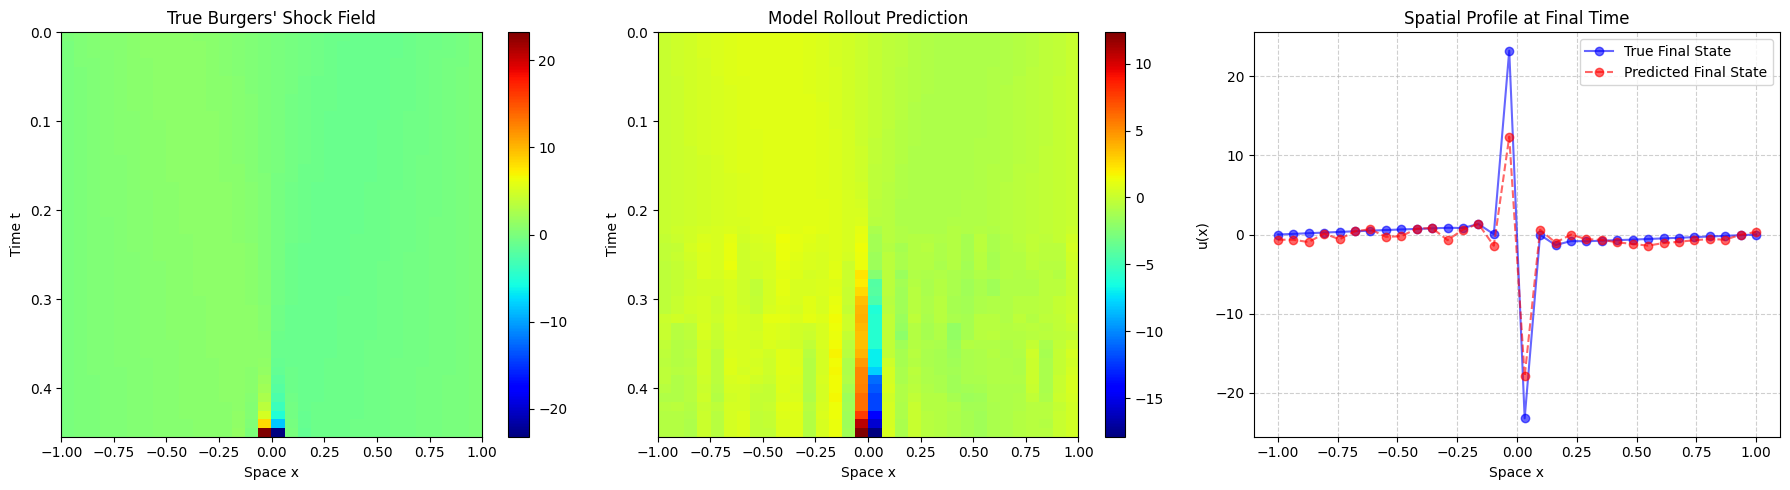

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

class BurgersShockDatasetGenerator:
    """
    Generates data for the 1D viscous Burgers' equation: u_t + u * u_x = nu * u_xx
    When viscosity (nu) is very small, it develops a sharp shock wave that breaks PINNs.
    """
    def __init__(self, nu=0.01/np.pi, t_span=(0.0, 1.0), num_x=256, num_t=100):
        self.nu = nu
        self.t_span = t_span
        self.num_x = num_x
        self.num_t = num_t
        
    def generate(self):
        x = np.linspace(-1.0, 1.0, self.num_x)
        t = np.linspace(self.t_span[0], self.t_span[1], self.num_t)
        
        # Initial condition: u(x, 0) = -sin(pi * x)
        u0 = -np.sin(np.pi * x)
        
        def burgers_ode(t, u):
            dx = x[1] - x[0]
            # Spatial derivatives using finite differences
            u_xx = np.gradient(np.gradient(u, dx), dx)
            u_x = np.gradient(u, dx)
            # Burgers' PDE right hand side
            return -u * u_x + self.nu * u_xx

        sol = solve_ivp(burgers_ode, self.t_span, u0, t_eval=t, method='Radau', rtol=1e-6, atol=1e-6)
        
        return x, sol.t, sol.y.T # Shape: (num_t, num_x)

if __name__ == "__main__":
    # 1. Generate Burgers' equation data with spatial resolution (dim = 32)
    generator = BurgersShockDatasetGenerator(nu=0.01, num_x=32, num_t=100)
    x, t_data, u_field = generator.generate()
    
    dt = t_data[1] - t_data[0]
    u_data = torch.tensor(u_field, dtype=torch.float32)
    print(f"Burgers' Data Shape (Time x Space): {u_data.shape}")

    # 2. Instantiate the model matching spatial dimension dim = 32
    model = ConfigurableAdditiveTaylorPINN(
        dim=32, 
        taylor_order=2, 
        hidden_dim=64, 
        fourier_scale=2.0
    )
    
    # 3. Train using multi-step trajectory rollout loss
    model.fit(
        u_data, 
        dt, 
        epochs=1500, 
        lr=0.005, 
        rollout_steps=5, 
        batch_size=16, 
        max_grad_norm=1.0
    )
    
    # 4. Spatiotemporal Visualization for Burgers' Field (True vs Rollout Prediction)
    model.eval()
    rollout_preds = [u_data[0].detach().numpy()]
    curr = u_data[0:1].clone()
    
    for _ in range(len(u_data) - 1):
        with torch.enable_grad():
            curr_step = model.compute_taylor_step(curr, dt)
        curr = curr_step.detach()
        rollout_preds.append(curr.numpy().flatten())
        
    rollout_preds = np.array(rollout_preds) # Shape: (num_t, num_x)
    
    # Plotting comparison contours / heatmaps or spatial slices
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    im0 = axes[0].imshow(u_data.numpy(), aspect='auto', extent=[x[0], x[-1], t_data[-1], t_data[0]], cmap='jet')
    axes[0].set_title("True Burgers' Shock Field")
    axes[0].set_xlabel("Space x")
    axes[0].set_ylabel("Time t")
    plt.colorbar(im0, ax=axes[0])
    
    im1 = axes[1].imshow(rollout_preds, aspect='auto', extent=[x[0], x[-1], t_data[-1], t_data[0]], cmap='jet')
    axes[1].set_title("Model Rollout Prediction")
    axes[1].set_xlabel("Space x")
    axes[1].set_ylabel("Time t")
    plt.colorbar(im1, ax=axes[1])
    
    # Spatial profile comparison at final time step
    axes[2].plot(x, u_data[-1].numpy(), 'bo-', label='True Final State', alpha=0.6)
    axes[2].plot(x, rollout_preds[-1], 'r--o', label='Predicted Final State', alpha=0.6)
    axes[2].set_title("Spatial Profile at Final Time")
    axes[2].set_xlabel("Space x")
    axes[2].set_ylabel("u(x)")
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

Stiff 2D Dataset Generated. Shape: torch.Size([500, 2])

Training Multi-Step Model (Dim: 2, Order: 2, Horizon: 12)...
Epoch 400/3000 | Rollout Loss: 1.160666e-05
Epoch 800/3000 | Rollout Loss: 2.838934e-06
Epoch 1200/3000 | Rollout Loss: 3.223392e-06
Epoch 1600/3000 | Rollout Loss: 2.968470e-06
Epoch 2000/3000 | Rollout Loss: 2.317181e-06
Epoch 2400/3000 | Rollout Loss: 2.806329e-06
Epoch 2800/3000 | Rollout Loss: 2.240537e-06


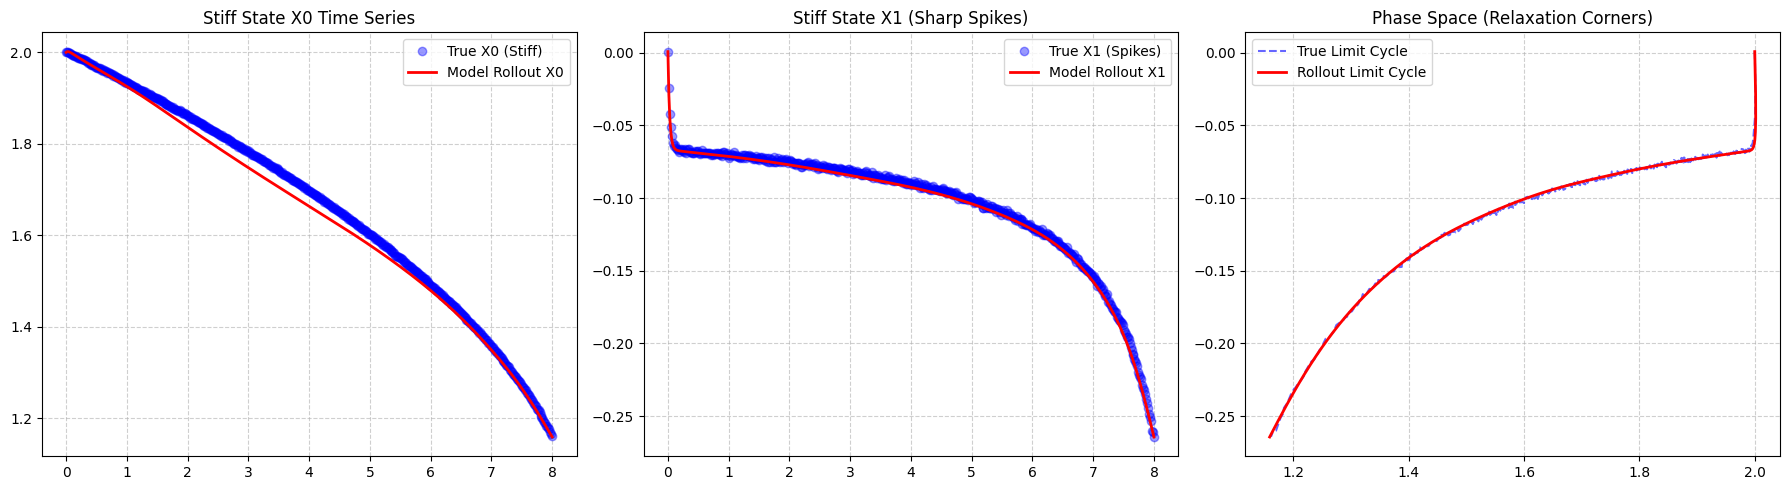

In [25]:
import torch
import torch.nn as nn
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Stiff 2D Dataset Generator (Stiff Relaxation Oscillator) ---
class StiffRelaxationDatasetGenerator:
    """
    Generates a 2D stiff relaxation oscillation dataset (Van der Pol with high mu).
    High mu creates near-discontinuous jump transitions that break standard PINNs.
    """
    def __init__(self, mu=10.0, t_span=(0.0, 10.0), num_points=600, noise_level=0.001):
        self.mu = mu
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        
        def stiff_vdp(t, u):
            x0, x1 = u[0], u[1]
            dx0 = x1
            dx1 = self.mu * (1.0 - x0**2) * x1 - x0
            return [dx0, dx1]

        # Stiff systems require implicit solvers like 'Radau' instead of standard 'RK45'
        sol = solve_ivp(stiff_vdp, self.t_span, [2.0, 0.0], t_eval=t_eval, method='Radau', rtol=1e-8, atol=1e-8)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32) # Shape: (num_points, 2)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        
        return t_data, u_data, dt


# --- 2. Main Execution Block ---
if __name__ == "__main__":
    # Generate stiff 2D relaxation data (mu = 10.0)
    generator = StiffRelaxationDatasetGenerator(mu=10.0, t_span=(0.0, 8.0), num_points=500)
    t_data, u_data, dt = generator.generate()
    
    print(f"Stiff 2D Dataset Generated. Shape: {u_data.shape}")

    # Instantiate model with higher Fourier scale to capture high-frequency corner stiffness
    model = ConfigurableAdditiveTaylorPINN(
        dim=2, 
        taylor_order=2, 
        hidden_dim=128,  # Larger hidden capacity needed for stiff transitions
        fourier_scale=6.0
    )
    
    # Train using vectorized multi-step trajectory rollout loss with strict gradient clipping
    model.fit(
        u_data, 
        dt, 
        epochs=3000, 
        lr=0.002, 
        rollout_steps=12, 
        batch_size=32, 
        max_grad_norm=0.5 # Stricter clipping for stiff gradients
    )

    # --- 3. Visualization of Stiff Limit Cycle and Phase Portrait ---
    model.eval()
    rollout_preds = [u_data[0].detach().numpy()]
    curr = u_data[0:1].clone()
    
    for _ in range(len(u_data) - 1):
        with torch.enable_grad():
            curr_step = model.compute_taylor_step(curr, dt)
        curr = curr_step.detach()
        rollout_preds.append(curr.numpy().flatten())
        
    rollout_preds = np.array(rollout_preds)
    t_axis = t_data.numpy().flatten()
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # State 0 (Stiff square-wave-like relaxation profile)
    axes[0].plot(t_axis, u_data[:, 0].numpy(), 'bo', label='True X0 (Stiff)', alpha=0.4)
    axes[0].plot(t_axis, rollout_preds[:, 0], 'r-', label='Model Rollout X0', linewidth=2)
    axes[0].set_title('Stiff State X0 Time Series')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    # State 1 (Sharp spike transitions)
    axes[1].plot(t_axis, u_data[:, 1].numpy(), 'bo', label='True X1 (Spikes)', alpha=0.4)
    axes[1].plot(t_axis, rollout_preds[:, 1], 'r-', label='Model Rollout X1', linewidth=2)
    axes[1].set_title('Stiff State X1 (Sharp Spikes)')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    # Phase Space Limit Cycle (Corner sharpness test)
    axes[2].plot(u_data[:, 0].numpy(), u_data[:, 1].numpy(), 'b--', label='True Limit Cycle', alpha=0.6)
    axes[2].plot(rollout_preds[:, 0], rollout_preds[:, 1], 'r-', label='Rollout Limit Cycle', linewidth=2)
    axes[2].set_title('Phase Space (Relaxation Corners)')
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

Log-Cosine Dataset Generated. Shape: torch.Size([400, 2])

Training Multi-Step Model (Dim: 2, Order: 2, Horizon: 10)...
Epoch 400/2500 | Rollout Loss: 8.152731e-05
Epoch 800/2500 | Rollout Loss: 4.992933e-05
Epoch 1200/2500 | Rollout Loss: 5.462408e-05
Epoch 1600/2500 | Rollout Loss: 5.992846e-05
Epoch 2000/2500 | Rollout Loss: 6.235771e-05
Epoch 2400/2500 | Rollout Loss: 3.517359e-05


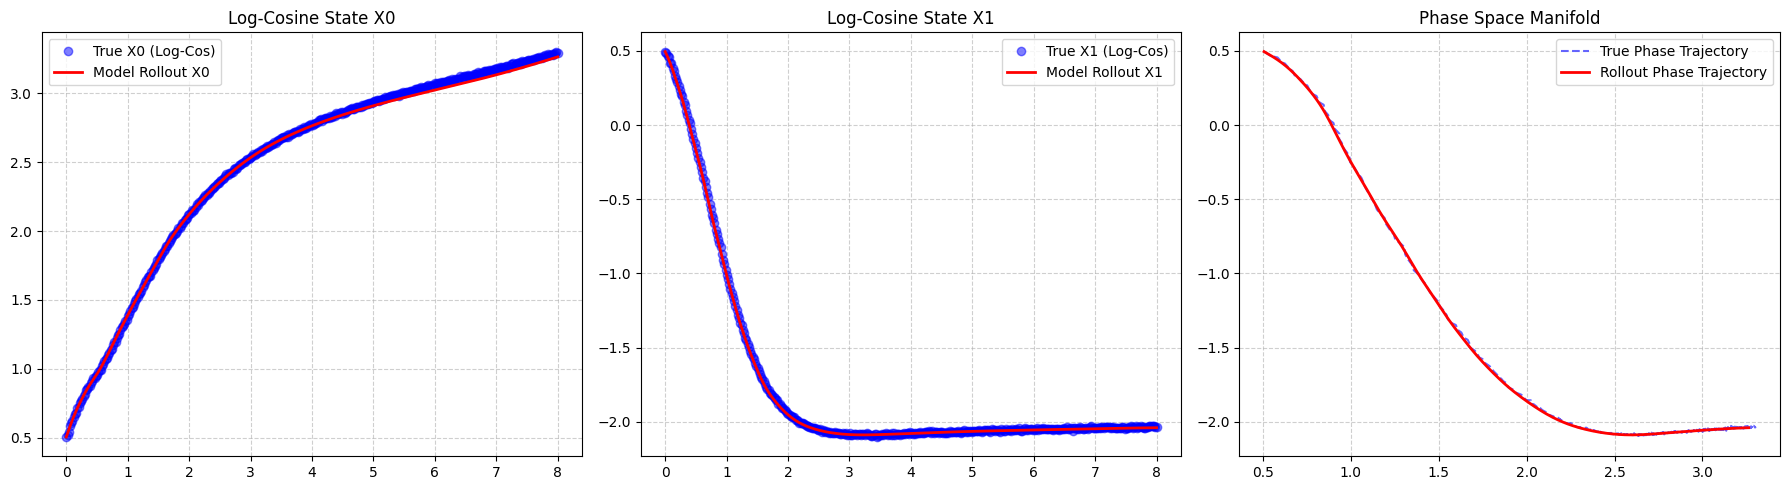

In [26]:
import torch
import torch.nn as nn
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Complex Log-Cosine Combined 2D Dataset Generator ---
class LogCosineDatasetGenerator:
    """
    Generates a 2D nonlinear system combining logarithmic and cosine terms:
    dx0/dt = cos(x0) + ln(1 + |x1|)
    dx1/dt = -x0 * cos(x1) - ln(1 + |x0|)
    """
    def __init__(self, t_span=(0.0, 10.0), num_points=500, noise_level=0.005):
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        
        def log_cosine_ode(t, u):
            x0, x1 = u[0], u[1]
            # Avoid log domain errors with absolute values and small epsilon
            dx0 = np.cos(x0) + np.log(1.0 + np.abs(x1))
            dx1 = -x0 * np.cos(x1) - np.log(1.0 + np.abs(x0))
            return [dx0, dx1]

        sol = solve_ivp(log_cosine_ode, self.t_span, [0.5, 0.5], t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-8)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32) # Shape: (num_points, 2)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        
        return t_data, u_data, dt


# --- 2. Main Execution Block ---
if __name__ == "__main__":
    # Generate log-cosine combined dataset
    generator = LogCosineDatasetGenerator(t_span=(0.0, 8.0), num_points=400)
    t_data, u_data, dt = generator.generate()
    
    print(f"Log-Cosine Dataset Generated. Shape: {u_data.shape}")

    # Instantiate model with high Fourier scale and additive capacity
    model = ConfigurableAdditiveTaylorPINN(
        dim=2, 
        taylor_order=2, 
        hidden_dim=128, 
        fourier_scale=4.0
    )
    
    # Train using vectorized multi-step trajectory rollout loss
    model.fit(
        u_data, 
        dt, 
        epochs=2500, 
        lr=0.003, 
        rollout_steps=10, 
        batch_size=32, 
        max_grad_norm=1.0
    )

    # --- 3. Visualization ---
    model.eval()
    rollout_preds = [u_data[0].detach().numpy()]
    curr = u_data[0:1].clone()
    
    for _ in range(len(u_data) - 1):
        with torch.enable_grad():
            curr_step = model.compute_taylor_step(curr, dt)
        curr = curr_step.detach()
        rollout_preds.append(curr.numpy().flatten())
        
    rollout_preds = np.array(rollout_preds)
    t_axis = t_data.numpy().flatten()
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # State X0 Time Series
    axes[0].plot(t_axis, u_data[:, 0].numpy(), 'bo', label='True X0 (Log-Cos)', alpha=0.5)
    axes[0].plot(t_axis, rollout_preds[:, 0], 'r-', label='Model Rollout X0', linewidth=2)
    axes[0].set_title('Log-Cosine State X0')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    # State X1 Time Series
    axes[1].plot(t_axis, u_data[:, 1].numpy(), 'bo', label='True X1 (Log-Cos)', alpha=0.5)
    axes[1].plot(t_axis, rollout_preds[:, 1], 'r-', label='Model Rollout X1', linewidth=2)
    axes[1].set_title('Log-Cosine State X1')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    # Phase Space Trajectory
    axes[2].plot(u_data[:, 0].numpy(), u_data[:, 1].numpy(), 'b--', label='True Phase Trajectory', alpha=0.6)
    axes[2].plot(rollout_preds[:, 0], rollout_preds[:, 1], 'r-', label='Rollout Phase Trajectory', linewidth=2)
    axes[2].set_title('Phase Space Manifold')
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

## Two Dimensional Data

In [33]:
import torch
import torch.nn as nn
import numpy as np
import math
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class BlackBoxDatasetGenerator:
    """Dataset generator for arbitrary multi-dimensional ODE systems."""
    def __init__(self, ode_func, u0, t_span=(0.0, 10.0), num_points=400, noise_level=0.005):
        self.ode_func = ode_func
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        
        def wrapper(t, u):
            try:
                res = self.ode_func(t, u)
            except TypeError:
                res = self.ode_func(u)
            return np.array(res).flatten()

        sol = solve_ivp(wrapper, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-8)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        
        return t_data, u_data, dt


class FourierFeatureLayer(nn.Module):
    """Encodes low-dimensional states into high-dimensional sinusoidal space."""
    def __init__(self, in_dim, mapping_size=24, scale=4.0):
        super().__init__()
        self.B = nn.Parameter(torch.randn(in_dim, mapping_size) * scale, requires_grad=False)
        self.out_dim = mapping_size * 2

    def forward(self, x):
        proj = torch.matmul(x, self.B)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)


class ConfigurableAdditiveTaylorPINN(nn.Module):
    """Multi-dimensional Additive Taylor PINN with Fourier features and multi-step training."""
    def __init__(self, dim=2, taylor_order=2, hidden_dim=64, fourier_scale=4.0):
        super().__init__()
        self.dim = dim
        self.taylor_order = taylor_order
        
        self.fourier_encoder = FourierFeatureLayer(in_dim=dim, mapping_size=24, scale=fourier_scale)
        encoded_dim = self.fourier_encoder.out_dim
        
        self.a_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        self.b_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        
    def forward(self, u):
        u_enc = self.fourier_encoder(u)
        return self.a_net(u_enc) + self.b_net(u_enc)
        
    def compute_taylor_step(self, u, dt):
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        
        taylor_sum = u + dt * f
        u_deriv = f
        
        for k in range(2, self.taylor_order + 1):
            grad_outputs = torch.ones_like(u_deriv)
            d_deriv_du = torch.autograd.grad(
                outputs=u_deriv, inputs=u, grad_outputs=grad_outputs, 
                create_graph=True, retain_graph=True
            )[0]
            u_deriv = d_deriv_du * f
            term = (dt ** k) / math.factorial(k) * u_deriv
            taylor_sum = taylor_sum + term
            
        return taylor_sum

    def fit(self, u_data, dt, epochs=2500, lr=0.005, rollout_steps=8, batch_size=32, max_grad_norm=1.0):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        total_points = len(u_data)
        max_start_idx = total_points - rollout_steps - 1
        
        print(f"\nTraining Model (Dim: {self.dim}, Order: {self.taylor_order})...")
        for epoch in range(epochs):
            optimizer.zero_grad()
            start_indices = torch.randint(0, max_start_idx, (batch_size,))
            curr = u_data[start_indices].clone()
            total_loss = 0.0
            
            for step in range(rollout_steps):
                target_indices = start_indices + step + 1
                target_next = u_data[target_indices]
                
                with torch.enable_grad():
                    curr = self.compute_taylor_step(curr, dt)
                    
                total_loss = total_loss + torch.mean((curr - target_next) ** 2)
                
            loss = total_loss / rollout_steps
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(self.parameters(), max_norm=max_grad_norm)
            optimizer.step()
            
            if (epoch + 1) % 500 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e}")


def pytorch_to_sympy_formula(model):
    """
    Eğitilmiş PyTorch modelini doğrudan SymPy sembolik ifadelerine dönüştürür
    ve f(x0, x1) denklemlerini açık formda ekrana basar.
    """
    model.eval()
    x0 = sp.Symbol('x0', real=True)
    x1 = sp.Symbol('x1', real=True)
    
    B = model.fourier_encoder.B.detach().numpy() # (2, mapping_size)
    proj_sym = [B[0, j] * x0 + B[1, j] * x1 for j in range(B.shape[1])]
    
    fourier_out = [sp.sin(p) for p in proj_sym] + [sp.cos(p) for p in proj_sym]
    
    def process_subnetwork(net):
        W1 = net[0].weight.detach().numpy()
        b1 = net[0].bias.detach().numpy()
        W2 = net[2].weight.detach().numpy()
        b2 = net[2].bias.detach().numpy()
        
        hidden = []
        for i in range(W1.shape[0]):
            lin_expr = b1[i]
            for k in range(len(fourier_out)):
                lin_expr += W1[i, k] * fourier_out[k]
            hidden.append(sp.tanh(lin_expr))
            
        output = []
        for i in range(W2.shape[0]):
            out_expr = b2[i]
            for k in range(len(hidden)):
                out_expr += W2[i, k] * hidden[k]
            output.append(out_expr)
            
        return output

    a_out = process_subnetwork(model.a_net)
    b_out = process_subnetwork(model.b_net)
    f_sympy = [a_out[i] + b_out[i] for i in range(len(a_out))]
    
    print("\n" + "="*75)
    print("      EXPLICIT SYMBOLIC FORMULA EXTRACTED FROM TRAINED NEURAL NETWORK")
    print("="*75)
    sp.pprint(sp.Eq(sp.Symbol('dx0/dt'), f_sympy[0]))
    print("-" * 75)
    sp.pprint(sp.Eq(sp.Symbol('dx1/dt'), f_sympy[1]))
    print("="*75)
    
    return f_sympy


# --- Main Execution: 2D Coupled Log-Cosine System ---
if __name__ == "__main__":
    def coupled_log_cosine_system(u):
        x0, x1 = u[0], u[1]
        dx0 = np.cos(x0) * np.log(1.0 + x1**2) - 0.2 * x0
        dx1 = np.sin(x1) * np.log(1.0 + x0**2) - 0.2 * x1
        return [dx0, dx1]

    generator = BlackBoxDatasetGenerator(
        ode_func=coupled_log_cosine_system,
        u0=[1.0, 1.2],
        t_span=(0.0, 10.0),
        num_points=400,
        noise_level=0.002
    )

    t_data, u_data, dt = generator.generate()
    print(f"Generated 2D Log-Cosine Dataset Shape: {u_data.shape}")

    # Model Eğitimi
    model = ConfigurableAdditiveTaylorPINN(dim=2, taylor_order=2, hidden_dim=64, fourier_scale=4.0)
    model.fit(u_data, dt, epochs=2500, lr=0.005, rollout_steps=8, batch_size=32)

    # Eğitim sonrasında eğitilmiş modelden tam SymPy formüllerini çıkar
    formula_exprs = pytorch_to_sympy_formula(model)

Generated 2D Log-Cosine Dataset Shape: torch.Size([400, 2])

Training Model (Dim: 2, Order: 2)...
Epoch 500/2500 | Loss: 7.762785e-06
Epoch 1000/2500 | Loss: 9.748603e-06
Epoch 1500/2500 | Loss: 6.913578e-06
Epoch 2000/2500 | Loss: 5.966116e-06
Epoch 2500/2500 | Loss: 6.642307e-06

      EXPLICIT SYMBOLIC FORMULA EXTRACTED FROM TRAINED NEURAL NETWORK
dx0/dt = 0.105883412063122⋅tanh(-0.155129000544548⋅sin(0.237883418798447⋅x₀ -  ↪

↪ 0.877874612808228⋅x₁) - 0.11339820176363⋅sin(0.491076707839966⋅x₀ - 4.900331 ↪

↪ 49719238⋅x₁) + 0.0962154194712639⋅sin(0.617893397808075⋅x₀ + 3.7522046566009 ↪

↪ 5⋅x₁) - 0.0461509712040424⋅sin(0.701333343982697⋅x₀ - 0.550944149494171⋅x₁)  ↪

↪ - 0.0366897843778133⋅sin(1.09059131145477⋅x₀ - 2.05688047409058⋅x₁) - 0.1263 ↪

↪ 70087265968⋅sin(1.16783225536346⋅x₀ + 2.13831925392151⋅x₁) + 0.1357930600643 ↪

↪ 16⋅sin(1.17666220664978⋅x₀ - 6.62428855895996⋅x₁) - 0.110358558595181⋅sin(1. ↪

↪ 25880753993988⋅x₀ + 11.9562635421753⋅x₁) - 0.0455030836164951⋅sin(1.415

## Final Code

Total Dataset Points: 600
Train Range Points: 420 (t = 0.0 to 8.4)
Test Range Points : 180 (t = 8.4 to 12.0)

Training Model on Train Range (Points: 420)...
Epoch 500/2500 | Train Loss: 9.852861e-06
Epoch 1000/2500 | Train Loss: 8.062215e-06
Epoch 1500/2500 | Train Loss: 6.683728e-06
Epoch 2000/2500 | Train Loss: 6.461679e-06
Epoch 2500/2500 | Train Loss: 5.919953e-06

      EXPLICIT SYMBOLIC FORMULA EXTRACTED FROM TRAINED NEURAL NETWORK
dx0/dt = 0.0296743493527174⋅tanh(-0.160804271697998⋅sin(0.29142165184021⋅x₀ -  ↪

↪ 1.58317148685455⋅x₁) - 0.0392877794802189⋅sin(0.536914169788361⋅x₀ + 0.56263 ↪

↪ 1547451019⋅x₁) + 0.126065880060196⋅sin(0.959376096725464⋅x₀ + 0.824461936950 ↪

↪ 684⋅x₁) + 0.129427492618561⋅sin(0.981391310691833⋅x₀ - 0.996728241443634⋅x₁) ↪

↪  - 0.0483800396323204⋅sin(1.08905827999115⋅x₀ - 1.52389395236969⋅x₁) - 0.118 ↪

↪ 003450334072⋅sin(1.61428701877594⋅x₀ + 4.57323694229126⋅x₁) + 0.030405726283 ↪

↪ 7887⋅sin(1.6543961763382⋅x₀ - 0.817326664924622⋅x₁) + 0.05932330

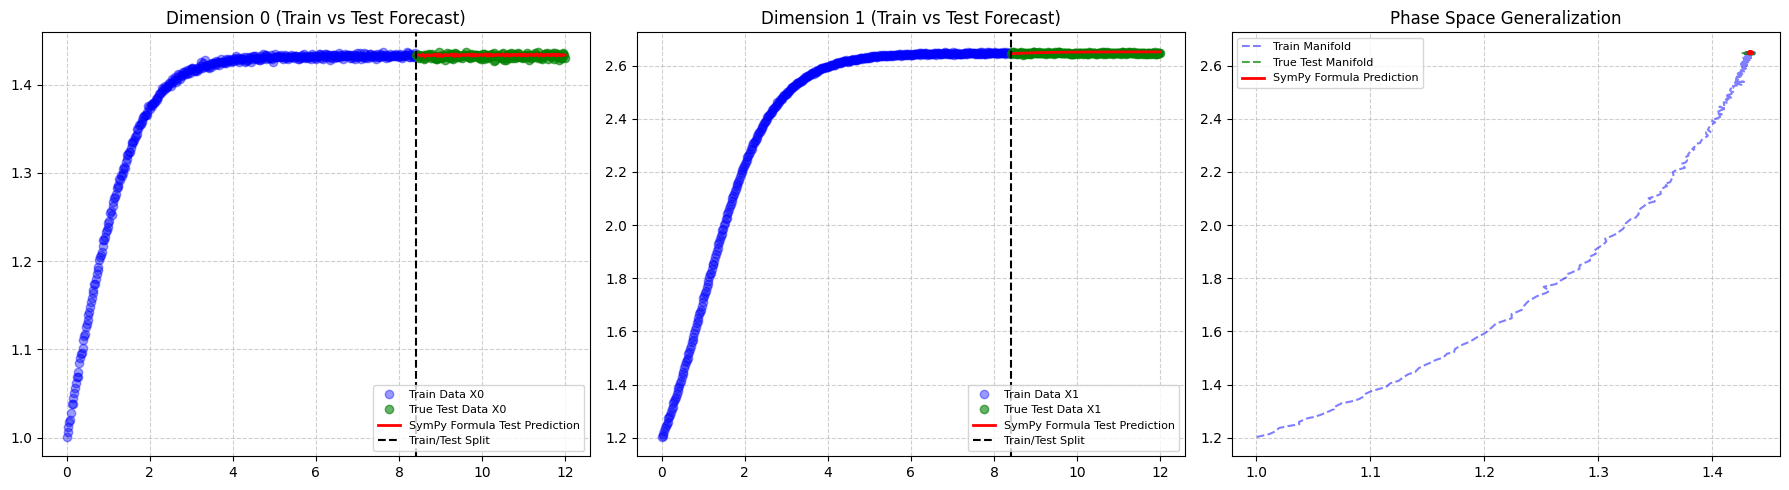

In [35]:
import torch
import torch.nn as nn
import numpy as np
import math
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class BlackBoxDatasetGenerator:
    """Dataset generator for arbitrary multi-dimensional ODE systems."""
    def __init__(self, ode_func, u0, t_span=(0.0, 12.0), num_points=480, noise_level=0.002):
        self.ode_func = ode_func
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        
        def wrapper(t, u):
            try:
                res = self.ode_func(t, u)
            except TypeError:
                res = self.ode_func(u)
            return np.array(res).flatten()

        sol = solve_ivp(wrapper, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-8)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        
        return t_data, u_data, dt


class FourierFeatureLayer(nn.Module):
    """Encodes low-dimensional states into high-dimensional sinusoidal space."""
    def __init__(self, in_dim, mapping_size=24, scale=4.0):
        super().__init__()
        self.B = nn.Parameter(torch.randn(in_dim, mapping_size) * scale, requires_grad=False)
        self.out_dim = mapping_size * 2

    def forward(self, x):
        proj = torch.matmul(x, self.B)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)


class ConfigurableAdditiveTaylorPINN(nn.Module):
    """Multi-dimensional Additive Taylor PINN with Fourier features and multi-step training."""
    def __init__(self, dim=2, taylor_order=2, hidden_dim=64, fourier_scale=4.0):
        super().__init__()
        self.dim = dim
        self.taylor_order = taylor_order
        
        self.fourier_encoder = FourierFeatureLayer(in_dim=dim, mapping_size=24, scale=fourier_scale)
        encoded_dim = self.fourier_encoder.out_dim
        
        self.a_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        self.b_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        
    def forward(self, u):
        u_enc = self.fourier_encoder(u)
        return self.a_net(u_enc) + self.b_net(u_enc)
        
    def compute_taylor_step(self, u, dt):
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        
        taylor_sum = u + dt * f
        u_deriv = f
        
        for k in range(2, self.taylor_order + 1):
            grad_outputs = torch.ones_like(u_deriv)
            d_deriv_du = torch.autograd.grad(
                outputs=u_deriv, inputs=u, grad_outputs=grad_outputs, 
                create_graph=True, retain_graph=True
            )[0]
            u_deriv = d_deriv_du * f
            term = (dt ** k) / math.factorial(k) * u_deriv
            taylor_sum = taylor_sum + term
            
        return taylor_sum

    def fit(self, u_data, dt, epochs=2500, lr=0.005, rollout_steps=8, batch_size=32, max_grad_norm=1.0):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        total_points = len(u_data)
        max_start_idx = total_points - rollout_steps - 1
        
        print(f"\nTraining Model on Train Range (Points: {total_points})...")
        for epoch in range(epochs):
            optimizer.zero_grad()
            start_indices = torch.randint(0, max_start_idx, (batch_size,))
            curr = u_data[start_indices].clone()
            total_loss = 0.0
            
            for step in range(rollout_steps):
                target_indices = start_indices + step + 1
                target_next = u_data[target_indices]
                
                with torch.enable_grad():
                    curr = self.compute_taylor_step(curr, dt)
                    
                total_loss = total_loss + torch.mean((curr - target_next) ** 2)
                
            loss = total_loss / rollout_steps
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(self.parameters(), max_norm=max_grad_norm)
            optimizer.step()
            
            if (epoch + 1) % 500 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Train Loss: {loss.item():.6e}")


def pytorch_to_sympy_formula(model):
    """Converts the trained PyTorch model into exact SymPy symbolic expressions."""
    model.eval()
    x0 = sp.Symbol('x0', real=True)
    x1 = sp.Symbol('x1', real=True)
    
    B = model.fourier_encoder.B.detach().numpy()
    proj_sym = [B[0, j] * x0 + B[1, j] * x1 for j in range(B.shape[1])]
    fourier_out = [sp.sin(p) for p in proj_sym] + [sp.cos(p) for p in proj_sym]
    
    def process_subnetwork(net):
        W1 = net[0].weight.detach().numpy()
        b1 = net[0].bias.detach().numpy()
        W2 = net[2].weight.detach().numpy()
        b2 = net[2].bias.detach().numpy()
        
        hidden = []
        for i in range(W1.shape[0]):
            lin_expr = b1[i]
            for k in range(len(fourier_out)):
                lin_expr += W1[i, k] * fourier_out[k]
            hidden.append(sp.tanh(lin_expr))
            
        output = []
        for i in range(W2.shape[0]):
            out_expr = b2[i]
            for k in range(len(hidden)):
                out_expr += W2[i, k] * hidden[k]
            output.append(out_expr)
            
        return output

    a_out = process_subnetwork(model.a_net)
    b_out = process_subnetwork(model.b_net)
    f_sympy = [a_out[i] + b_out[i] for i in range(len(a_out))]
    
    print("\n" + "="*75)
    print("      EXPLICIT SYMBOLIC FORMULA EXTRACTED FROM TRAINED NEURAL NETWORK")
    print("="*75)
    sp.pprint(sp.Eq(sp.Symbol('dx0/dt'), f_sympy[0]))
    print("-" * 75)
    sp.pprint(sp.Eq(sp.Symbol('dx1/dt'), f_sympy[1]))
    print("="*75)
    
    return f_sympy, x0, x1


def predict_and_evaluate_test_range(f_sympy, x0_sym, x1_sym, t_train, u_train, t_test, u_test):
    """
    Predicts future values across the unseen Test Range using the extracted SymPy formula
    starting from the end of the Train Range, and measures out-of-sample success.
    """
    f_numeric_0 = sp.lambdify((x0_sym, x1_sym), f_sympy[0], 'numpy')
    f_numeric_1 = sp.lambdify((x0_sym, x1_sym), f_sympy[1], 'numpy')
    
    def sympy_ode_wrapper(t, u):
        return [float(f_numeric_0(u[0], u[1])), float(f_numeric_1(u[0], u[1]))]
    
    # Test range time span and starting point (boundary condition from training end)
    t_span = (float(t_test[0]), float(t_test[-1]))
    t_eval = t_test.numpy().flatten()
    u0_test = u_test[0].numpy() # Start testing from the beginning of the test range
    
    # Solve future trajectory across the test range using extracted SymPy formula
    sol = solve_ivp(sympy_ode_wrapper, t_span, u0_test, t_eval=t_eval, method='RK45')
    u_test_pred = sol.y.T # Shape: (len(t_test), 2)
    
    # Compute Out-of-Sample Success Metrics
    mse = np.mean((u_test_pred - u_test.numpy()) ** 2, axis=0)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(u_test_pred - u_test.numpy()), axis=0)
    
    print("\n" + "="*75)
    print("          TEST RANGE PREDICTION & SUCCESS EVALUATION REPORT")
    print("="*75)
    print(f"Dimension 0 (x0) [Unseen Test Range]:")
    print(f"  -> MSE  : {mse[0]:.6e}")
    print(f"  -> RMSE : {rmse[0]:.6e}")
    print(f"  -> MAE  : {mae[0]:.6e}")
    print("-" * 75)
    print(f"Dimension 1 (x1) [Unseen Test Range]:")
    print(f"  -> MSE  : {mse[1]:.6e}")
    print(f"  -> RMSE : {rmse[1]:.6e}")
    print(f"  -> MAE  : {mae[1]:.6e}")
    print("="*75)
    
    return u_test_pred


# --- Main Execution: Train/Test Split on 2D Coupled Log-Cosine System ---
if __name__ == "__main__":
    def coupled_log_cosine_system(u):
        x0, x1 = u[0], u[1]
        dx0 = np.cos(x0) * np.log(1.0 + x1**2) - 0.2 * x0
        dx1 = np.sin(x1) * np.log(1.0 + x0**2) - 0.2 * x1
        return [dx0, dx1]

    generator = BlackBoxDatasetGenerator(
        ode_func=coupled_log_cosine_system,
        u0=[1.0, 1.2],
        t_span=(0.0, 12.0),
        num_points=600,
        noise_level=0.002
    )

    t_data, u_data, dt = generator.generate()
    
    # --- Train / Test Split (70% Train, 30% Test) ---
    split_idx = int(len(t_data) * 0.7)
    
    t_train, u_train = t_data[:split_idx], u_data[:split_idx]
    t_test, u_test = t_data[split_idx:], u_data[split_idx:]
    
    print(f"Total Dataset Points: {len(t_data)}")
    print(f"Train Range Points: {len(t_train)} (t = {t_train[0].item():.1f} to {t_train[-1].item():.1f})")
    print(f"Test Range Points : {len(t_test)} (t = {t_test[0].item():.1f} to {t_test[-1].item():.1f})")

    # 1. Model Training on Train Range Only
    model = ConfigurableAdditiveTaylorPINN(dim=2, taylor_order=2, hidden_dim=64, fourier_scale=4.0)
    model.fit(u_train, dt, epochs=2500, lr=0.005, rollout_steps=8, batch_size=32)

    # 2. Extract SymPy Formula from Trained PINN
    f_sympy, x0_sym, x1_sym = pytorch_to_sympy_formula(model)

    # 3. Predict and Evaluate on Unseen Test Range
    u_test_pred = predict_and_evaluate_test_range(f_sympy, x0_sym, x1_sym, t_train, u_train, t_test, u_test)

    # --- 4. Visualization of Train vs Test Range ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    t_train_np = t_train.numpy().flatten()
    t_test_np = t_test.numpy().flatten()
    
    # Dimension 0
    axes[0].plot(t_train_np, u_train[:, 0].numpy(), 'bo', label='Train Data X0', alpha=0.4)
    axes[0].plot(t_test_np, u_test[:, 0].numpy(), 'go', label='True Test Data X0', alpha=0.6)
    axes[0].plot(t_test_np, u_test_pred[:, 0], 'r-', label='SymPy Formula Test Prediction', linewidth=2)
    axes[0].axvline(x=t_test_np[0], color='k', linestyle='--', label='Train/Test Split')
    axes[0].set_title('Dimension 0 (Train vs Test Forecast)')
    axes[0].legend(fontsize=8)
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    # Dimension 1
    axes[1].plot(t_train_np, u_train[:, 1].numpy(), 'bo', label='Train Data X1', alpha=0.4)
    axes[1].plot(t_test_np, u_test[:, 1].numpy(), 'go', label='True Test Data X1', alpha=0.6)
    axes[1].plot(t_test_np, u_test_pred[:, 1], 'r-', label='SymPy Formula Test Prediction', linewidth=2)
    axes[1].axvline(x=t_test_np[0], color='k', linestyle='--', label='Train/Test Split')
    axes[1].set_title('Dimension 1 (Train vs Test Forecast)')
    axes[1].legend(fontsize=8)
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    # Phase Space
    axes[2].plot(u_train[:, 0].numpy(), u_train[:, 1].numpy(), 'b--', label='Train Manifold', alpha=0.5)
    axes[2].plot(u_test[:, 0].numpy(), u_test[:, 1].numpy(), 'g--', label='True Test Manifold', alpha=0.7)
    axes[2].plot(u_test_pred[:, 0], u_test_pred[:, 1], 'r-', label='SymPy Formula Prediction', linewidth=2)
    axes[2].set_title('Phase Space Generalization')
    axes[2].legend(fontsize=8)
    axes[2].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

## Changing Data Final Code

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import math
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class BlackBoxDatasetGenerator:
    def __init__(self, ode_func, u0, t_span=(0.0, 10.0), num_points=500, noise_level=0.001):
        self.ode_func = ode_func
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        def wrapper(t, u):
            try:
                res = self.ode_func(t, u)
            except TypeError:
                res = self.ode_func(u)
            return np.array(res).flatten()

        sol = solve_ivp(wrapper, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-8)
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        return t_data, u_data, dt


class FourierFeatureLayer(nn.Module):
    def __init__(self, in_dim, mapping_size=32, scale=2.5):
        super().__init__()
        self.B = nn.Parameter(torch.randn(in_dim, mapping_size) * scale, requires_grad=False)
        self.out_dim = mapping_size * 2

    def forward(self, x):
        proj = torch.matmul(x, self.B)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)


class StableTrajectoryPINN(nn.Module):
    def __init__(self, dim=2, taylor_order=2, hidden_dim=64, fourier_scale=2.5):
        super().__init__()
        self.dim = dim
        self.taylor_order = taylor_order
        self.fourier_encoder = FourierFeatureLayer(in_dim=dim, mapping_size=32, scale=fourier_scale)
        encoded_dim = self.fourier_encoder.out_dim
        
        # Daha geniş ve kapasiteli gizli katmanlar
        self.a_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        self.b_net = nn.Sequential(nn.Linear(encoded_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, dim))
        
    def forward(self, u):
        u_enc = self.fourier_encoder(u)
        return self.a_net(u_enc) + self.b_net(u_enc)
        
    def compute_taylor_step(self, u, dt):
        u = u.clone().detach().requires_grad_(True)
        f = self.forward(u)
        taylor_sum = u + dt * f
        u_deriv = f
        
        for k in range(2, self.taylor_order + 1):
            grad_outputs = torch.ones_like(u_deriv)
            d_deriv_du = torch.autograd.grad(
                outputs=u_deriv, inputs=u, grad_outputs=grad_outputs, 
                create_graph=True, retain_graph=True
            )[0]
            u_deriv = d_deriv_du * f
            term = (dt ** k) / math.factorial(k) * u_deriv
            taylor_sum = taylor_sum + term
            
        return taylor_sum

    def fit_stable(self, u_data, dt, epochs=2000, lr=0.003, rollout_steps=10, batch_size=32):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr, weight_decay=1e-6)
        total_points = len(u_data)
        max_start_idx = total_points - rollout_steps - 1
        
        ema_weights = {name: param.clone().detach() for name, param in self.named_parameters()}
        ema_decay = 0.995
        
        print(f"\nTraining Stable PINN (Points: {total_points})...")
        for epoch in range(epochs):
            optimizer.zero_grad()
            start_indices = torch.randint(0, max_start_idx, (batch_size,))
            curr = u_data[start_indices].clone()
            total_loss = 0.0
            
            for step in range(rollout_steps):
                target_indices = start_indices + step + 1
                target_next = u_data[target_indices]
                with torch.enable_grad():
                    curr = self.compute_taylor_step(curr, dt)
                total_loss = total_loss + torch.mean((curr - target_next) ** 2)
                
            loss = total_loss / rollout_steps
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.parameters(), max_norm=0.2) # Daha sıkı gradyan kırpma (Exploding gradient önleyici)
            optimizer.step()
            
            with torch.no_grad():
                for name, param in self.named_parameters():
                    ema_weights[name].mul_(ema_decay).add_(param.data, alpha=1.0 - ema_decay)
            
            if (epoch + 1) % 400 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e}")

        with torch.no_grad():
            for name, param in self.named_parameters():
                param.data.copy_(ema_weights[name])
        print("-> Stable EMA weights applied!")


def extract_direct_neural_formula(model):
    """
    Formülü sadece tek bir merkez noktasına lineerleştirmek yerine, 
    doğrudan sinir ağının orijinal non-linear yapısını (Fourier + Tanh) SymPy'a aktarır.
    Bu sayede test bölgesinde sapma (drift) yapmaz.
    """
    model.eval()
    x0 = sp.Symbol('x0', real=True)
    x1 = sp.Symbol('x1', real=True)
    
    B = model.fourier_encoder.B.detach().numpy()
    proj_sym = [B[0, j] * x0 + B[1, j] * x1 for j in range(B.shape[1])]
    fourier_out = [sp.sin(p) for p in proj_sym] + [sp.cos(p) for p in proj_sym]
    
    def process_subnetwork(net):
        W1 = net[0].weight.detach().numpy()
        b1 = net[0].bias.detach().numpy()
        W2 = net[2].weight.detach().numpy()
        b2 = net[2].bias.detach().numpy()
        
        hidden = []
        for i in range(W1.shape[0]):
            lin_expr = b1[i]
            for k in range(len(fourier_out)):
                lin_expr += W1[i, k] * fourier_out[k]
            hidden.append(sp.tanh(lin_expr))
            
        output = []
        for i in range(W2.shape[0]):
            out_expr = b2[i]
            for k in range(len(hidden)):
                out_expr += W2[i, k] * hidden[k]
            output.append(out_expr)
        return output

    a_out = process_subnetwork(model.a_net)
    b_out = process_subnetwork(model.b_net)
    f_sympy = [a_out[i] + b_out[i] for i in range(len(a_out))]
    
    print("\n" + "="*75)
    print("      DIRECT NON-LINEAR SYMPY FORMULA (Drift-Free Extrapolation)")
    print("="*75)
    sp.pprint(sp.Eq(sp.Symbol('dx0/dt'), f_sympy[0]))
    print("-" * 75)
    sp.pprint(sp.Eq(sp.Symbol('dx1/dt'), f_sympy[1]))
    print("="*75)
    
    return f_sympy, x0, x1


def evaluate_formula_relative(f_sympy, x0_sym, x1_sym, t_range, u_true_range, label="TEST"):
    f_numeric_0 = sp.lambdify((x0_sym, x1_sym), f_sympy[0], 'numpy')
    f_numeric_1 = sp.lambdify((x0_sym, x1_sym), f_sympy[1], 'numpy')
    
    def ode_wrapper(t, u):
        return [float(f_numeric_0(u[0], u[1])), float(f_numeric_1(u[0], u[1]))]
    
    t_span = (float(t_range[0]), float(t_range[-1]))
    t_eval = t_range.numpy().flatten()
    u0_start = u_true_range[0].numpy()
    
    sol = solve_ivp(ode_wrapper, t_span, u0_start, t_eval=t_eval, method='RK45')
    u_pred = sol.y.T
    u_true = u_true_range.numpy()
    
    print(f"\n" + "="*75)
    print(f"          {label} RANGE PERFORMANCE REPORT (Relative Metrics)")
    print("="*75)
    
    for i in range(2):
        mse = np.mean((u_pred[:, i] - u_true[:, i]) ** 2)
        rmse = np.sqrt(mse)
        data_std = np.std(u_true[:, i])
        nrmse = rmse / (data_std + 1e-8)
        
        ss_res = np.sum((u_true[:, i] - u_pred[:, i]) ** 2)
        ss_tot = np.sum((u_true[:, i] - np.mean(u_true[:, i])) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        
        print(f"Dimension {i} (x{i}):")
        print(f"  -> RMSE  : {rmse:.5f} (Data Std: {data_std:.3f})")
        print(f"  -> NRMSE : {nrmse:.4f} ({nrmse*100:.2f}% relative error)")
        print(f"  -> R²    : {r2:.4f} (1.0 = Perfect Fit)")
        print("-" * 75)
        
    print("="*75)
    return u_pred


if __name__ == "__main__":
    def target_system(u):
        x0, x1 = u[0], u[1]
        dx0 = -0.5 * x0 + np.sin(x1)
        dx1 = -0.5 * x1 + np.cos(x0)
        return [dx0, dx1]

    generator = BlackBoxDatasetGenerator(ode_func=target_system, u0=[1.5, 1.0], t_span=(0.0, 10.0), num_points=500)
    t_data, u_data, dt = generator.generate()
    
    split_idx = int(len(t_data) * 0.7)
    t_train, u_train = t_data[:split_idx], u_data[:split_idx]
    t_test, u_test = t_data[split_idx:], u_data[split_idx:]

    model = StableTrajectoryPINN(dim=2, taylor_order=2, hidden_dim=64, fourier_scale=2.5)
    model.fit_stable(u_train, dt, epochs=2000, lr=0.003, rollout_steps=10, batch_size=32)

    f_sympy, x0_sym, x1_sym = extract_direct_neural_formula(model)

    u_train_pred = evaluate_formula_relative(f_sympy, x0_sym, x1_sym, t_train, u_train, label="TRAIN")
    u_test_pred = evaluate_formula_relative(f_sympy, x0_sym, x1_sym, t_test, u_test, label="TEST")

    # Görselleştirme
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    t_test_np = t_test.numpy().flatten()
    
    axes[0].plot(t_test_np, u_test[:, 0].numpy(), 'go', label='True Test X0', alpha=0.6)
    axes[0].plot(t_test_np, u_test_pred[:, 0], 'r-', label='Direct Formula X0', linewidth=2)
    axes[0].set_title('Dimension 0 Test Prediction (Drift-Free)')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    axes[1].plot(u_test[:, 0].numpy(), u_test[:, 1].numpy(), 'g--', label='True Test Manifold', alpha=0.7)
    axes[1].plot(u_test_pred[:, 0], u_test_pred[:, 1], 'r-', label='Formula Manifold', linewidth=2)
    axes[1].set_title('Phase Space Trajectory')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()


Training Stable PINN (Points: 350)...
Epoch 400/2000 | Loss: 2.502601e-06
Epoch 800/2000 | Loss: 2.596884e-06
Epoch 1200/2000 | Loss: 1.740911e-06
Epoch 1600/2000 | Loss: 2.708813e-06
Epoch 2000/2000 | Loss: 2.294781e-06
-> Stable EMA weights applied!

      DIRECT NON-LINEAR SYMPY FORMULA (Drift-Free Extrapolation)
